# Adolescent Smartphone Use & Well-Being — Exploratory Data Analysis

**Research question**

> Among adolescents with comparable levels of smartphone exposure, which behavioral, lifestyle, and psychosocial factors are associated with differences in well-being?

### Purpose of this notebook
This notebook begins the EDA process before formal modeling. It will:

1. Load and inspect the raw Teen Phone Addiction dataset.
2. Check shape, columns, data types, missing values, duplicates, and ID uniqueness.
3. Summarize numeric and categorical variables.
4. Visualize important distributions.
5. Examine initial relationships between total smartphone use and well-being-related outcomes.
6. Review correlations with anxiety, depression, self-esteem, sleep, and academic performance.
7. Explore smartphone-behavior variables separately from well-being variables.
8. Create **temporary exploratory usage groups** to examine variation among adolescents with comparable smartphone exposure.

> **Important:** The usage groups created near the end are exploratory only. They are not yet the final method for defining "comparable smartphone exposure."


## 1. Setup

### Recommended VS Code project structure

```text
Adolescent_Smartphone_Wellbeing/
│
├── data/
│   └── teen_phone_addiction_dataset.csv
│
├── notebooks/
│   └── Adolescent_Smartphone_Wellbeing_EDA.ipynb
│
└── outputs/
    └── figures/
```

If your notebook is inside the `notebooks` folder and the CSV is inside the `data` folder, the default path below should work.

If not, change **only `DATA_PATH`** in the next cell.


In [1]:
# If needed, install packages once in your VS Code terminal:
# pip install pandas numpy matplotlib scipy scikit-learn

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path(
    r"C:\Users\thelo\OneDrive\Documentos\School\MSDS692\Teen Phone Addiction DATASET\teen_phone_addiction_dataset.csv"
)

print(DATA_PATH)
print("File exists:", DATA_PATH.exists())


C:\Users\thelo\OneDrive\Documentos\School\MSDS692\Teen Phone Addiction DATASET\teen_phone_addiction_dataset.csv
File exists: True


## 2. Load the dataset

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find the dataset at: {DATA_PATH.resolve()}\n"
        "Update DATA_PATH in the setup cell to point to your CSV file."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")


Dataset loaded successfully.
Rows: 3,000
Columns: 25


## 3. Initial structure and first look

In [3]:
print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())


Dataset shape:
(3000, 25)

Column names:
['ID', 'Name', 'Age', 'Gender', 'Location', 'School_Grade', 'Daily_Usage_Hours', 'Sleep_Hours', 'Academic_Performance', 'Social_Interactions', 'Exercise_Hours', 'Anxiety_Level', 'Depression_Level', 'Self_Esteem', 'Parental_Control', 'Screen_Time_Before_Bed', 'Phone_Checks_Per_Day', 'Apps_Used_Daily', 'Time_on_Social_Media', 'Time_on_Gaming', 'Time_on_Education', 'Phone_Usage_Purpose', 'Family_Communication', 'Weekend_Usage_Hours', 'Addiction_Level']

First five rows:


,ID,Name,Age,Gender,Location,School_Grade,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,...,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Phone_Usage_Purpose,Family_Communication,Weekend_Usage_Hours,Addiction_Level
0,1,Shannon Francis,13,Female,Hansonfort,9th,4.0,6.1,78,5,...,1.4,86,19,3.6,1.7,1.2,Browsing,4,8.7,10.0
1,2,Scott Rodriguez,17,Female,Theodorefort,7th,5.5,6.5,70,5,...,0.9,96,9,1.1,4.0,1.8,Browsing,2,5.3,10.0
2,3,Adrian Knox,13,Other,Lindseystad,11th,5.8,5.5,93,8,...,0.5,137,8,0.3,1.5,0.4,Education,6,5.7,9.2
3,4,Brittany Hamilton,18,Female,West Anthony,12th,3.1,3.9,78,8,...,1.4,128,7,3.1,1.6,0.8,Social Media,8,3.0,9.8
4,5,Steven Smith,14,Other,Port Lindsaystad,9th,2.5,6.7,56,4,...,1.0,96,20,2.6,0.9,1.1,Gaming,10,3.7,8.6


In [4]:
print("Dataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      3000 non-null   int64  
 1   Name                    3000 non-null   str    
 2   Age                     3000 non-null   int64  
 3   Gender                  3000 non-null   str    
 4   Location                3000 non-null   str    
 5   School_Grade            3000 non-null   str    
 6   Daily_Usage_Hours       3000 non-null   float64
 7   Sleep_Hours             3000 non-null   float64
 8   Academic_Performance    3000 non-null   int64  
 9   Social_Interactions     3000 non-null   int64  
 10  Exercise_Hours          3000 non-null   float64
 11  Anxiety_Level           3000 non-null   int64  
 12  Depression_Level        3000 non-null   int64  
 13  Self_Esteem             3000 non-null   int64  
 14  Parental_Control        3000 n

### What to note
As you inspect the output, record:

- Are there 3,000 rows and 25 columns?
- Do numeric-looking variables have numeric data types?
- Are categorical variables stored as text/object?
- Are any columns unexpectedly empty?
- Are there obvious identifiers that should eventually be excluded from modeling, such as `ID` and `Name`?


## 4. Review data types

In [5]:
dtype_summary = pd.DataFrame({
    "Data_Type": df.dtypes,
    "Non_Null_Count": df.notna().sum(),
    "Unique_Values": df.nunique()
})

display(dtype_summary)


,Data_Type,Non_Null_Count,Unique_Values
ID,int64,3000,3000
Name,str,3000,2933
Age,int64,3000,7
Gender,str,3000,3
Location,str,3000,2726
School_Grade,str,3000,6
Daily_Usage_Hours,float64,3000,107
Sleep_Hours,float64,3000,71
Academic_Performance,int64,3000,51
Social_Interactions,int64,3000,11


## 5. Check missing values

In [6]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

display(missing_summary)

print(f"Total missing cells: {df.isna().sum().sum():,}")


,Missing_Count,Missing_Percent
ID,0,0.0
Name,0,0.0
Age,0,0.0
Gender,0,0.0
Location,0,0.0
School_Grade,0,0.0
Daily_Usage_Hours,0,0.0
Sleep_Hours,0,0.0
Academic_Performance,0,0.0
Social_Interactions,0,0.0


Total missing cells: 0


## 6. Check duplicate rows and participant IDs

In [7]:
duplicate_rows = df.duplicated().sum()

print(f"Duplicate rows: {duplicate_rows:,}")
print(f"Total rows: {len(df):,}")
print(f"Unique IDs: {df['ID'].nunique():,}")

if df["ID"].nunique() == len(df):
    print("ID appears unique for every row.")
else:
    print("WARNING: Some IDs appear more than once.")


Duplicate rows: 0
Total rows: 3,000
Unique IDs: 3,000
ID appears unique for every row.


In [8]:
# Optional: inspect duplicate rows if any exist
if duplicate_rows > 0:
    display(df[df.duplicated(keep=False)].sort_values("ID"))
else:
    print("No exact duplicate rows found.")


No exact duplicate rows found.


## 7. Descriptive statistics for numeric variables

In [9]:
numeric_summary = df.describe(include=[np.number]).T
display(numeric_summary)


,count,mean,std,min,25%,50%,75%,max
ID,3000.0,1500.500000,866.169729,1.0,750.75,1500.5,2250.25,3000.0
Age,3000.0,15.969667,1.989489,13.0,14.00,16.0,18.00,19.0
Daily_Usage_Hours,3000.0,5.020667,1.956501,0.0,3.70,5.0,6.40,11.5
Sleep_Hours,3000.0,6.489767,1.490713,3.0,5.50,6.5,7.50,10.0
Academic_Performance,3000.0,74.947333,14.684156,50.0,62.00,75.0,88.00,100.0
Social_Interactions,3000.0,5.097667,3.139333,0.0,2.00,5.0,8.00,10.0
Exercise_Hours,3000.0,1.040667,0.734620,0.0,0.50,1.0,1.50,4.0
Anxiety_Level,3000.0,5.590000,2.890678,1.0,3.00,6.0,8.00,10.0
Depression_Level,3000.0,5.460333,2.871557,1.0,3.00,5.0,8.00,10.0
Self_Esteem,3000.0,5.546333,2.860754,1.0,3.00,6.0,8.00,10.0


### Variables to pay special attention to
For this research question, inspect the ranges and distributions of:

- `Daily_Usage_Hours`
- `Weekend_Usage_Hours`
- `Phone_Checks_Per_Day`
- `Screen_Time_Before_Bed`
- `Time_on_Social_Media`
- `Time_on_Gaming`
- `Time_on_Education`
- `Sleep_Hours`
- `Exercise_Hours`
- `Social_Interactions`
- `Family_Communication`
- `Anxiety_Level`
- `Depression_Level`
- `Self_Esteem`
- `Academic_Performance`

Look for values that seem impossible, extreme, or unexpectedly concentrated.


## 8. Categorical-variable distributions

In [10]:
categorical_columns = [
    "Gender",
    "Location",
    "School_Grade",
    "Phone_Usage_Purpose"
]

for column in categorical_columns:
    print(f"\n{'=' * 60}")
    print(column)
    print("=" * 60)

    counts = df[column].value_counts(dropna=False)
    percentages = (df[column].value_counts(dropna=False, normalize=True) * 100).round(2)

    category_summary = pd.DataFrame({
        "Count": counts,
        "Percent": percentages
    })

    display(category_summary)



Gender


,Count,Percent
Gender,,
Male,1016,33.87
Female,1007,33.57
Other,977,32.57



Location


,Count,Percent
Location,,
North Michael,6,0.20
Lake Michael,5,0.17
North Christopher,4,0.13
Lake James,4,0.13
South Michael,4,0.13
...,...,...
New Jennifer,1,0.03
Richardport,1,0.03
Rebeccaton,1,0.03



School_Grade


,Count,Percent
School_Grade,,
12th,529,17.63
9th,526,17.53
7th,497,16.57
10th,487,16.23
8th,482,16.07
11th,479,15.97



Phone_Usage_Purpose


,Count,Percent
Phone_Usage_Purpose,,
Browsing,627,20.90
Other,622,20.73
Education,602,20.07
Social Media,575,19.17
Gaming,574,19.13


## 9. Visualize important numeric distributions

In [11]:
def plot_histogram(data, column, bins=20, xlabel=None):
    """Plot a simple histogram for one numeric variable."""
    plt.figure(figsize=(8, 5))
    plt.hist(data[column].dropna(), bins=bins, edgecolor="black")
    plt.xlabel(xlabel if xlabel else column)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {column}")
    plt.tight_layout()
    plt.show()


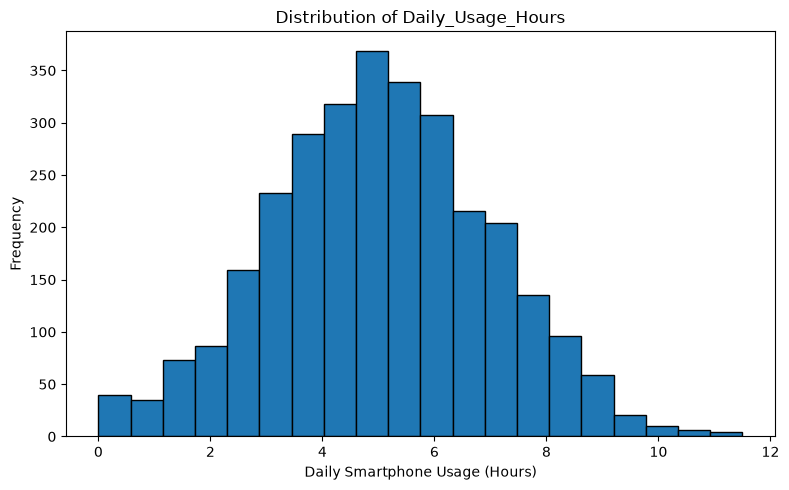

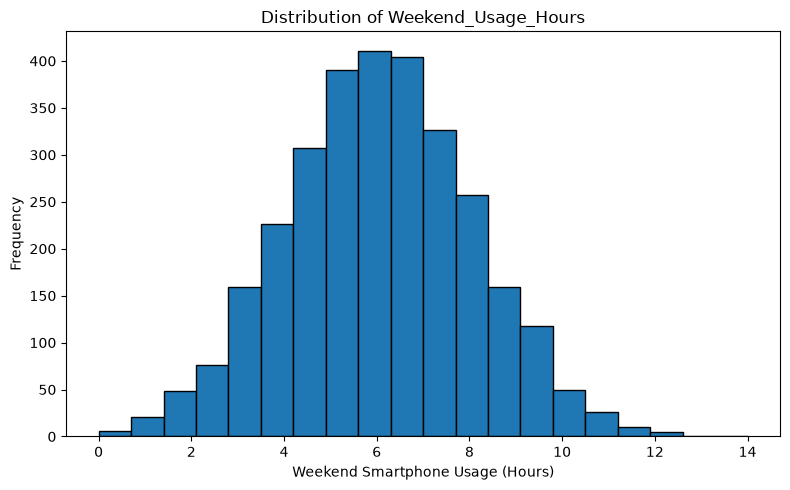

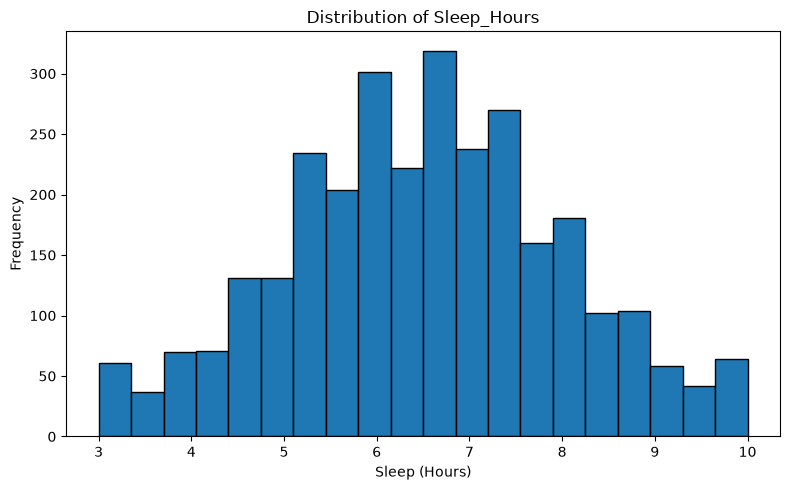

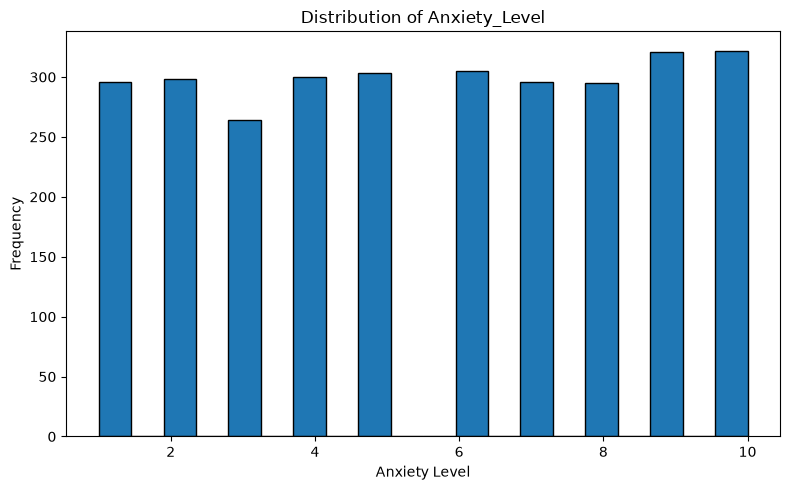

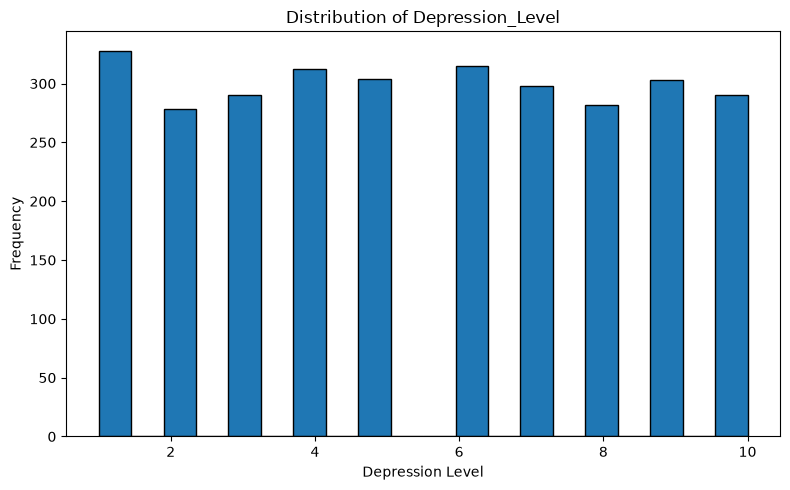

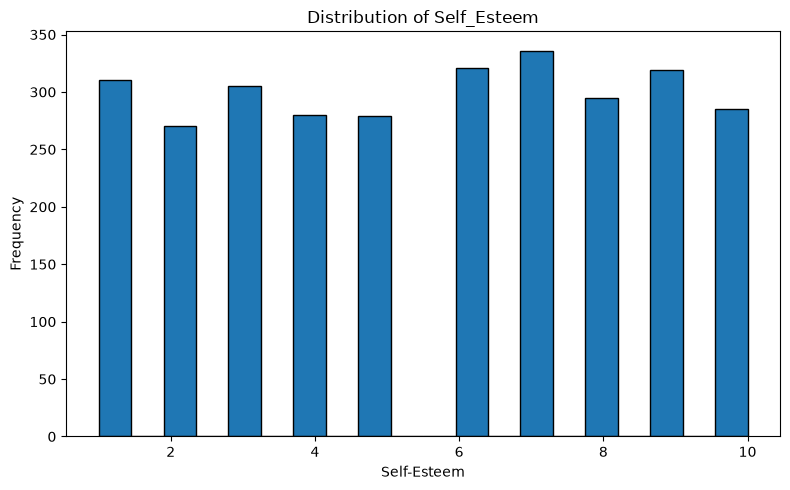

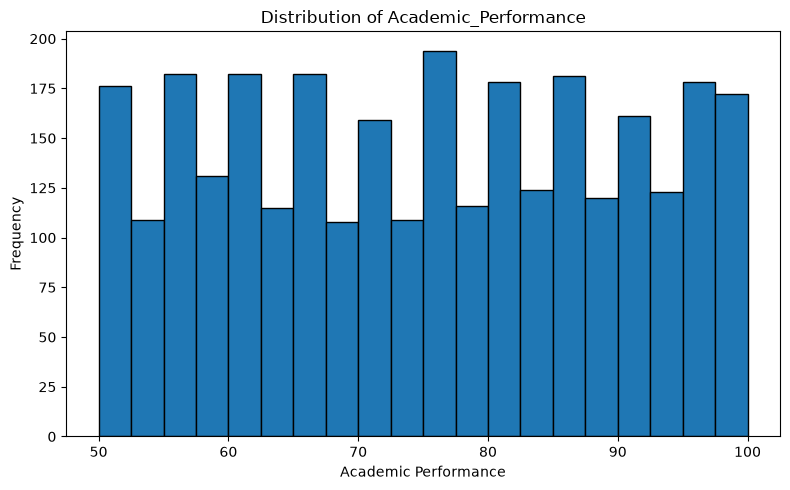

In [12]:
# Begin with the variables most central to the research question
plot_histogram(df, "Daily_Usage_Hours", xlabel="Daily Smartphone Usage (Hours)")
plot_histogram(df, "Weekend_Usage_Hours", xlabel="Weekend Smartphone Usage (Hours)")
plot_histogram(df, "Sleep_Hours", xlabel="Sleep (Hours)")
plot_histogram(df, "Anxiety_Level", xlabel="Anxiety Level")
plot_histogram(df, "Depression_Level", xlabel="Depression Level")
plot_histogram(df, "Self_Esteem", xlabel="Self-Esteem")
plot_histogram(df, "Academic_Performance", xlabel="Academic Performance")


### Questions to ask while viewing the distributions
- Are the variables approximately symmetric or strongly skewed?
- Are there ceiling or floor effects?
- Are there obvious outliers?
- Are some scales highly concentrated around only a few values?
- Does a variable appear continuous, ordinal, or categorical despite its numeric data type?


## 10. Smartphone exposure vs. well-being-related outcomes

In [13]:
def plot_exposure_scatter(data, outcome, ylabel=None):
    """Scatterplot of daily smartphone exposure against one outcome."""
    plt.figure(figsize=(8, 5))
    plt.scatter(
        data["Daily_Usage_Hours"],
        data[outcome],
        alpha=0.30
    )
    plt.xlabel("Daily Smartphone Usage (Hours)")
    plt.ylabel(ylabel if ylabel else outcome)
    plt.title(f"Daily Smartphone Usage vs {outcome}")
    plt.tight_layout()
    plt.show()


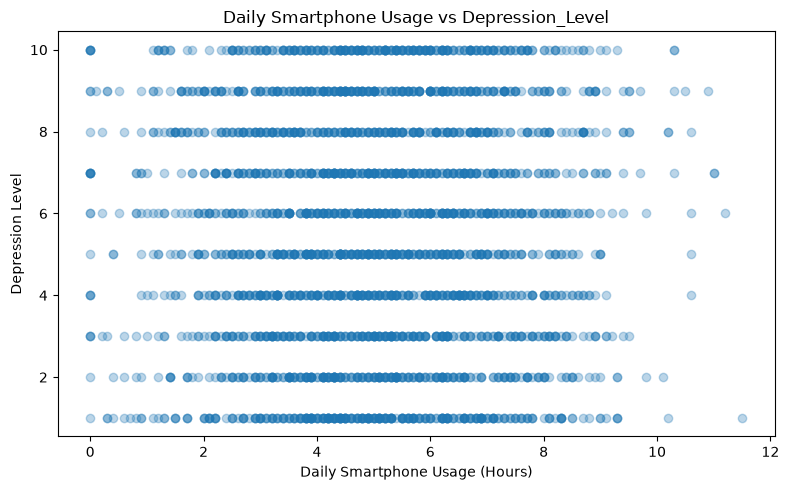

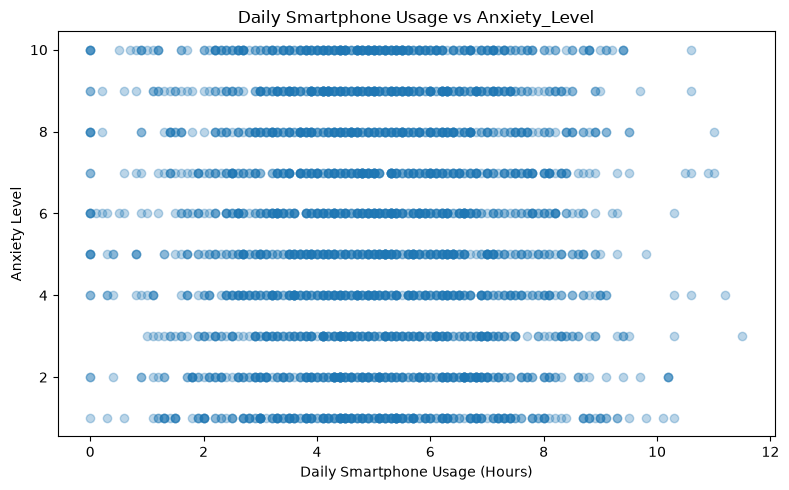

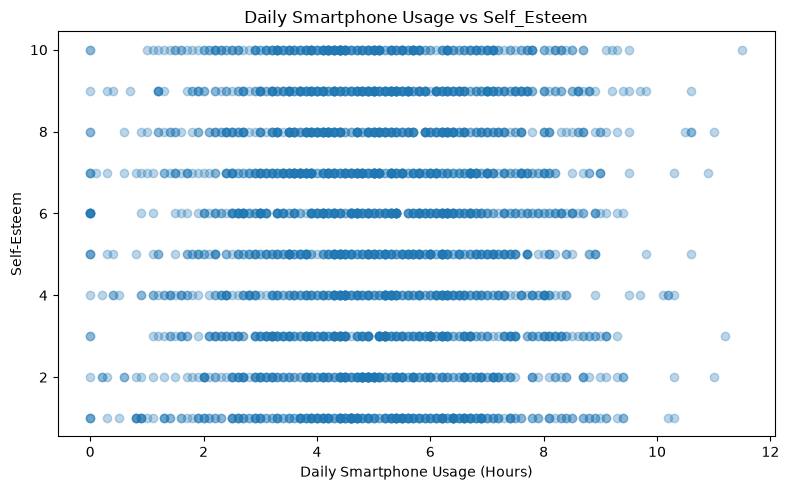

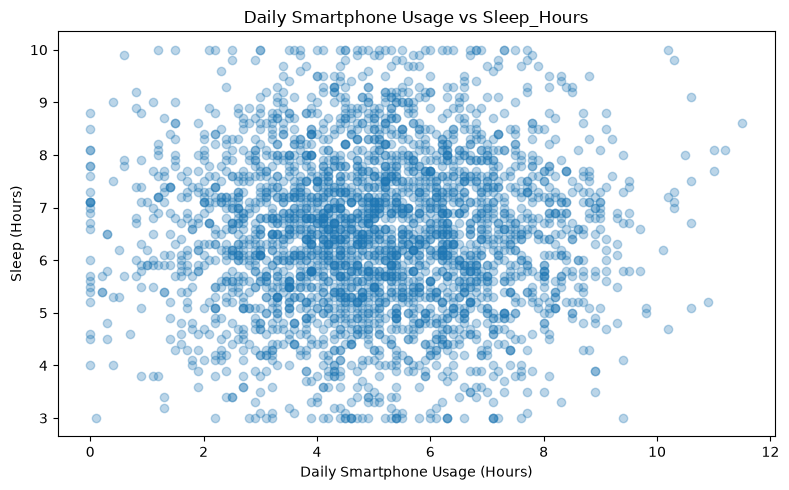

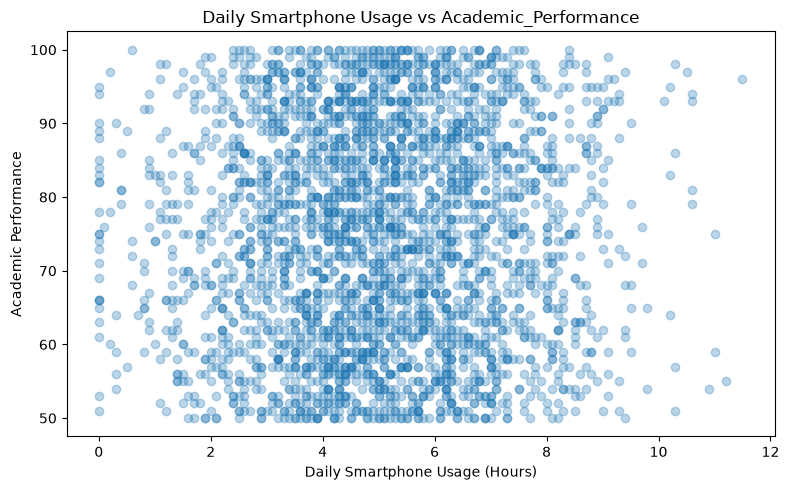

In [14]:
plot_exposure_scatter(df, "Depression_Level", "Depression Level")
plot_exposure_scatter(df, "Anxiety_Level", "Anxiety Level")
plot_exposure_scatter(df, "Self_Esteem", "Self-Esteem")
plot_exposure_scatter(df, "Sleep_Hours", "Sleep (Hours)")
plot_exposure_scatter(df, "Academic_Performance", "Academic Performance")


### What matters for the research question
Do **not** look only for an upward or downward trend.

Also look **vertically** within similar values of `Daily_Usage_Hours`.

For example, if adolescents near 6 hours/day show very different depression, anxiety, self-esteem, sleep, or academic scores, that variation supports the core premise of the project:

> Adolescents with similar smartphone exposure can have substantially different well-being outcomes.

The next stages of the project will investigate what distinguishes them.


## 11. Correlation analysis

In [15]:
numeric_df = df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(2))


,ID,Age,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,Exercise_Hours,Anxiety_Level,Depression_Level,Self_Esteem,Parental_Control,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Family_Communication,Weekend_Usage_Hours,Addiction_Level
ID,1.00,-0.04,-0.00,0.02,-0.01,-0.04,0.00,0.01,0.00,-0.01,-0.02,0.00,-0.04,-0.00,0.02,0.01,-0.00,-0.02,0.02,-0.01
Age,-0.04,1.00,0.04,0.01,0.02,-0.02,0.00,0.01,0.05,-0.03,0.03,0.01,-0.01,-0.00,-0.01,-0.01,0.01,-0.00,0.00,0.03
Daily_Usage_Hours,-0.00,0.04,1.00,0.02,0.02,-0.03,-0.01,-0.01,0.01,0.01,0.00,0.00,0.00,0.02,-0.01,-0.01,0.01,0.00,0.02,0.60
Sleep_Hours,0.02,0.01,0.02,1.00,-0.00,-0.02,0.01,0.01,-0.01,0.02,0.01,-0.00,0.01,0.03,-0.02,0.01,-0.01,-0.03,-0.00,-0.22
Academic_Performance,-0.01,0.02,0.02,-0.00,1.00,0.01,-0.00,0.00,-0.03,-0.01,0.00,-0.01,-0.02,-0.03,0.04,-0.03,0.02,-0.03,0.01,0.01
Social_Interactions,-0.04,-0.02,-0.03,-0.02,0.01,1.00,0.01,0.00,0.02,0.01,-0.02,-0.02,0.01,-0.03,0.00,-0.00,-0.01,0.00,-0.02,-0.01
Exercise_Hours,0.00,0.00,-0.01,0.01,-0.00,0.01,1.00,0.00,-0.01,-0.01,0.02,0.02,-0.01,-0.01,-0.02,-0.01,0.02,0.01,0.04,-0.02
Anxiety_Level,0.01,0.01,-0.01,0.01,0.00,0.00,0.00,1.00,0.02,0.00,-0.01,-0.00,0.02,0.01,-0.00,0.01,0.02,0.01,0.01,0.02
Depression_Level,0.00,0.05,0.01,-0.01,-0.03,0.02,-0.01,0.02,1.00,-0.03,0.01,-0.03,-0.00,0.02,0.00,-0.01,-0.03,-0.01,-0.01,0.01
Self_Esteem,-0.01,-0.03,0.01,0.02,-0.01,0.01,-0.01,0.00,-0.03,1.00,-0.03,0.00,-0.01,-0.03,-0.01,-0.01,-0.01,-0.03,-0.04,-0.02


In [16]:
outcomes_of_interest = [
    "Depression_Level",
    "Anxiety_Level",
    "Self_Esteem",
    "Sleep_Hours",
    "Academic_Performance"
]

for outcome in outcomes_of_interest:
    print(f"\n{'=' * 70}")
    print(f"Correlations with {outcome}")
    print("=" * 70)
    display(
        correlation_matrix[outcome]
        .drop(outcome)
        .sort_values(ascending=False)
        .to_frame("Correlation")
    )



Correlations with Depression_Level


,Correlation
Age,0.052699
Social_Interactions,0.024195
Apps_Used_Daily,0.019049
Anxiety_Level,0.018607
Parental_Control,0.014949
Daily_Usage_Hours,0.009672
Addiction_Level,0.008491
ID,0.004777
Time_on_Social_Media,0.001758
Phone_Checks_Per_Day,-0.001146



Correlations with Anxiety_Level


,Correlation
Time_on_Education,0.024640
Depression_Level,0.018607
Phone_Checks_Per_Day,0.017988
Addiction_Level,0.016005
Time_on_Gaming,0.014677
Age,0.014651
Family_Communication,0.011090
Sleep_Hours,0.009836
ID,0.008810
Apps_Used_Daily,0.007416



Correlations with Self_Esteem


,Correlation
Sleep_Hours,0.016488
Social_Interactions,0.008314
Daily_Usage_Hours,0.006340
Anxiety_Level,0.003951
Screen_Time_Before_Bed,0.003562
Academic_Performance,-0.005459
Phone_Checks_Per_Day,-0.005905
ID,-0.006017
Time_on_Gaming,-0.007537
Time_on_Education,-0.008804



Correlations with Sleep_Hours


,Correlation
Apps_Used_Daily,0.026436
ID,0.018254
Self_Esteem,0.016488
Daily_Usage_Hours,0.016444
Age,0.014725
Anxiety_Level,0.009836
Exercise_Hours,0.006814
Time_on_Gaming,0.005798
Parental_Control,0.005670
Phone_Checks_Per_Day,0.005198



Correlations with Academic_Performance


,Correlation
Time_on_Social_Media,0.036357
Age,0.023481
Daily_Usage_Hours,0.021345
Time_on_Education,0.016377
Weekend_Usage_Hours,0.014263
Addiction_Level,0.012264
Social_Interactions,0.011815
Anxiety_Level,0.003427
Parental_Control,0.003186
Sleep_Hours,-0.000273


### Correlation caution
Correlation is useful for EDA, but it does **not** establish causation.

At this stage, use correlations to identify patterns and variables worth investigating further—not to make causal conclusions about smartphone use or adolescent well-being.


## 12. Organize variables by their role in the research question

In [17]:
phone_behavior_columns = [
    "Daily_Usage_Hours",
    "Weekend_Usage_Hours",
    "Phone_Checks_Per_Day",
    "Screen_Time_Before_Bed",
    "Apps_Used_Daily",
    "Time_on_Social_Media",
    "Time_on_Gaming",
    "Time_on_Education"
]

lifestyle_columns = [
    "Sleep_Hours",
    "Exercise_Hours",
    "Social_Interactions",
    "Family_Communication"
]

psychosocial_columns = [
    "Anxiety_Level",
    "Depression_Level",
    "Self_Esteem"
]

other_outcome_columns = [
    "Academic_Performance"
]

print("Phone behavior variables:")
display(df[phone_behavior_columns].describe().T)

print("Lifestyle variables:")
display(df[lifestyle_columns].describe().T)

print("Psychosocial variables:")
display(df[psychosocial_columns].describe().T)

print("Academic outcome:")
display(df[other_outcome_columns].describe().T)


Phone behavior variables:


,count,mean,std,min,25%,50%,75%,max
Daily_Usage_Hours,3000.0,5.020667,1.956501,0.0,3.7,5.0,6.40,11.5
Weekend_Usage_Hours,3000.0,6.015100,2.014776,0.0,4.7,6.0,7.40,14.0
Phone_Checks_Per_Day,3000.0,83.093000,37.747044,20.0,51.0,82.0,115.25,150.0
Screen_Time_Before_Bed,3000.0,1.006733,0.492878,0.0,0.7,1.0,1.40,2.6
Apps_Used_Daily,3000.0,12.609333,4.611486,5.0,9.0,13.0,17.00,20.0
Time_on_Social_Media,3000.0,2.499233,0.988201,0.0,1.8,2.5,3.20,5.0
Time_on_Gaming,3000.0,1.525267,0.932701,0.0,0.8,1.5,2.20,4.0
Time_on_Education,3000.0,1.016333,0.648341,0.0,0.5,1.0,1.50,3.0


Lifestyle variables:


,count,mean,std,min,25%,50%,75%,max
Sleep_Hours,3000.0,6.489767,1.490713,3.0,5.5,6.5,7.5,10.0
Exercise_Hours,3000.0,1.040667,0.734620,0.0,0.5,1.0,1.5,4.0
Social_Interactions,3000.0,5.097667,3.139333,0.0,2.0,5.0,8.0,10.0
Family_Communication,3000.0,5.459667,2.864572,1.0,3.0,5.0,8.0,10.0


Psychosocial variables:


,count,mean,std,min,25%,50%,75%,max
Anxiety_Level,3000.0,5.590000,2.890678,1.0,3.0,6.0,8.0,10.0
Depression_Level,3000.0,5.460333,2.871557,1.0,3.0,5.0,8.0,10.0
Self_Esteem,3000.0,5.546333,2.860754,1.0,3.0,6.0,8.0,10.0


Academic outcome:


,count,mean,std,min,25%,50%,75%,max
Academic_Performance,3000.0,74.947333,14.684156,50.0,62.0,75.0,88.0,100.0


### Important methodological note
These groups are organizational aids only.

In particular, this notebook does **not** assume that anxiety, depression, self-esteem, sleep, social functioning, and academic performance should automatically be combined into one well-being score.

Whether the final project uses:

- separate outcomes,
- a theoretically justified composite score,
- dimensionality reduction such as PCA,
- or another approach

should be decided after EDA and methodological review.


## 13. Exploratory comparable-use groups

The following usage bands are **temporary EDA categories**. They are useful for seeing whether well-being varies within approximately comparable levels of smartphone exposure.

They are **not yet the final analysis method**.


In [18]:
df["Usage_Group"] = pd.cut(
    df["Daily_Usage_Hours"],
    bins=[0, 3, 5, 7, float("inf")],
    labels=[
        "0-3 hours",
        "3-5 hours",
        "5-7 hours",
        "7+ hours"
    ],
    include_lowest=True
)

print("Number of adolescents in each exploratory usage group:")
display(df["Usage_Group"].value_counts().sort_index().to_frame("Count"))


Number of adolescents in each exploratory usage group:


,Count
Usage_Group,
0-3 hours,470
3-5 hours,1075
5-7 hours,1001
7+ hours,454


In [19]:
group_outcomes = [
    "Depression_Level",
    "Anxiety_Level",
    "Self_Esteem",
    "Sleep_Hours",
    "Academic_Performance"
]

for outcome in group_outcomes:
    print(f"\n{'=' * 70}")
    print(f"{outcome} by exploratory smartphone-use group")
    print("=" * 70)

    display(
        df.groupby("Usage_Group", observed=True)[outcome]
        .describe()
        .round(2)
    )



Depression_Level by exploratory smartphone-use group


,count,mean,std,min,25%,50%,75%,max
Usage_Group,,,,,,,,
0-3 hours,470.0,5.56,2.83,1.0,3.0,6.0,8.0,10.0
3-5 hours,1075.0,5.37,2.88,1.0,3.0,5.0,8.0,10.0
5-7 hours,1001.0,5.51,2.87,1.0,3.0,6.0,8.0,10.0
7+ hours,454.0,5.47,2.90,1.0,3.0,6.0,8.0,10.0



Anxiety_Level by exploratory smartphone-use group


,count,mean,std,min,25%,50%,75%,max
Usage_Group,,,,,,,,
0-3 hours,470.0,5.44,2.88,1.0,3.0,5.0,8.0,10.0
3-5 hours,1075.0,5.70,2.89,1.0,3.0,6.0,8.0,10.0
5-7 hours,1001.0,5.55,2.88,1.0,3.0,6.0,8.0,10.0
7+ hours,454.0,5.56,2.91,1.0,3.0,6.0,8.0,10.0



Self_Esteem by exploratory smartphone-use group


,count,mean,std,min,25%,50%,75%,max
Usage_Group,,,,,,,,
0-3 hours,470.0,5.31,2.86,1.0,3.0,5.0,8.0,10.0
3-5 hours,1075.0,5.68,2.89,1.0,3.0,6.0,8.0,10.0
5-7 hours,1001.0,5.50,2.84,1.0,3.0,6.0,8.0,10.0
7+ hours,454.0,5.57,2.84,1.0,3.0,6.0,8.0,10.0



Sleep_Hours by exploratory smartphone-use group


,count,mean,std,min,25%,50%,75%,max
Usage_Group,,,,,,,,
0-3 hours,470.0,6.44,1.46,3.0,5.5,6.5,7.4,10.0
3-5 hours,1075.0,6.47,1.48,3.0,5.5,6.5,7.4,10.0
5-7 hours,1001.0,6.52,1.53,3.0,5.4,6.5,7.6,10.0
7+ hours,454.0,6.51,1.47,3.0,5.5,6.6,7.4,10.0



Academic_Performance by exploratory smartphone-use group


,count,mean,std,min,25%,50%,75%,max
Usage_Group,,,,,,,,
0-3 hours,470.0,74.25,14.00,50.0,62.25,74.0,85.75,100.0
3-5 hours,1075.0,74.72,14.82,50.0,61.00,75.0,88.00,100.0
5-7 hours,1001.0,75.39,14.98,50.0,62.00,76.0,88.00,100.0
7+ hours,454.0,75.23,14.40,50.0,63.00,75.5,87.00,100.0


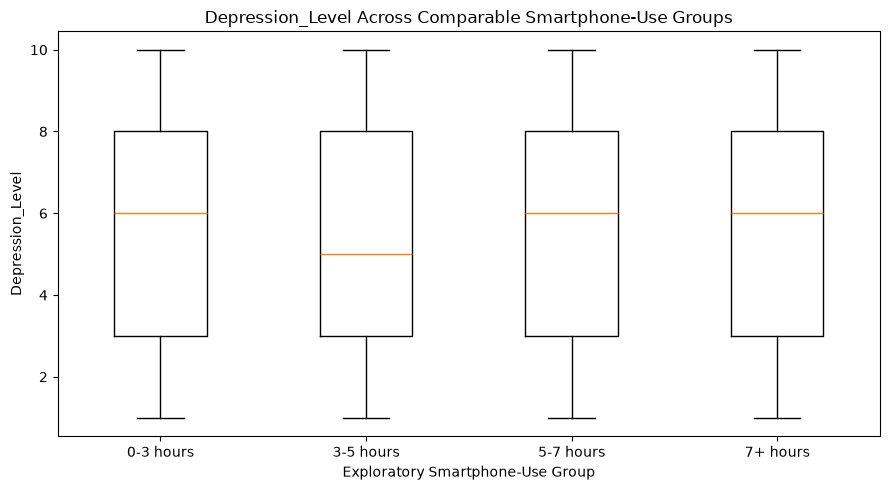

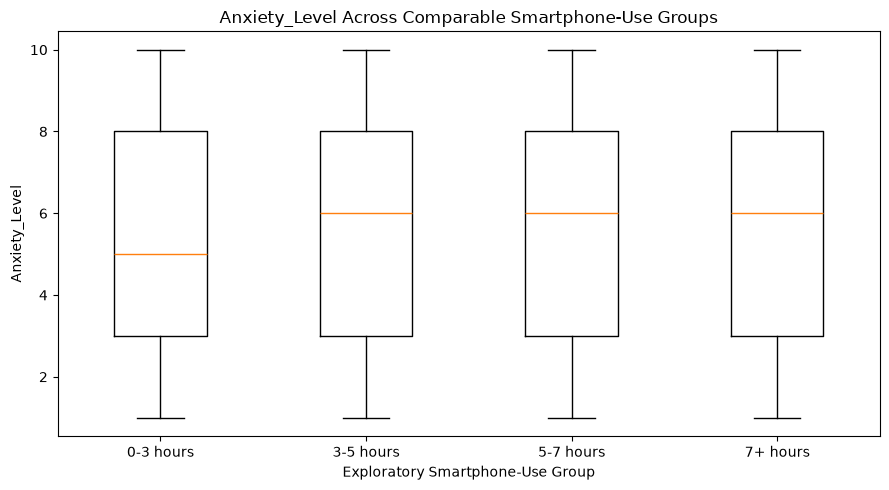

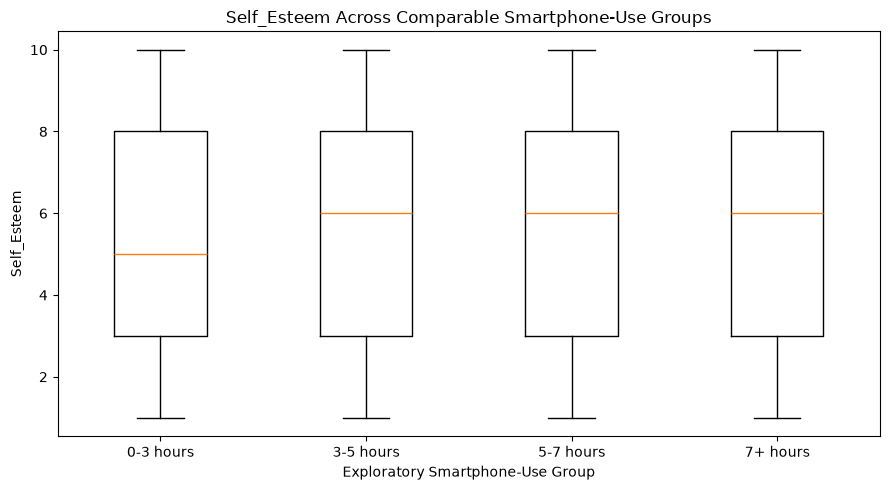

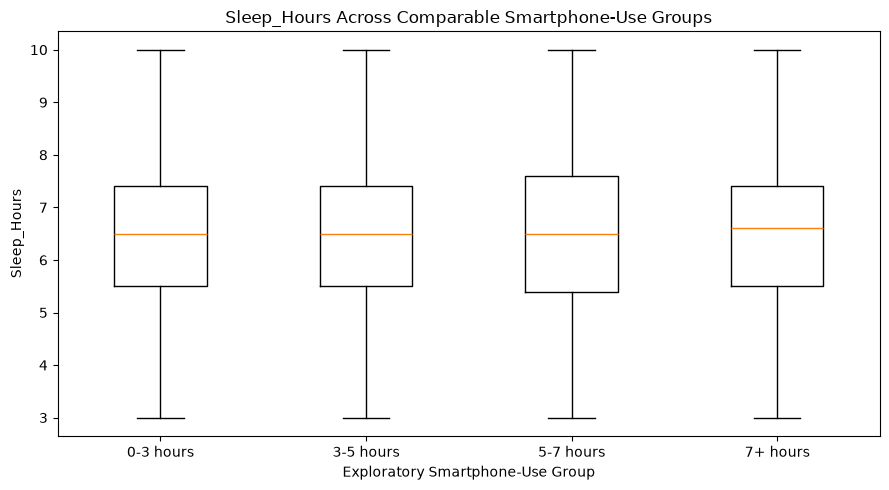

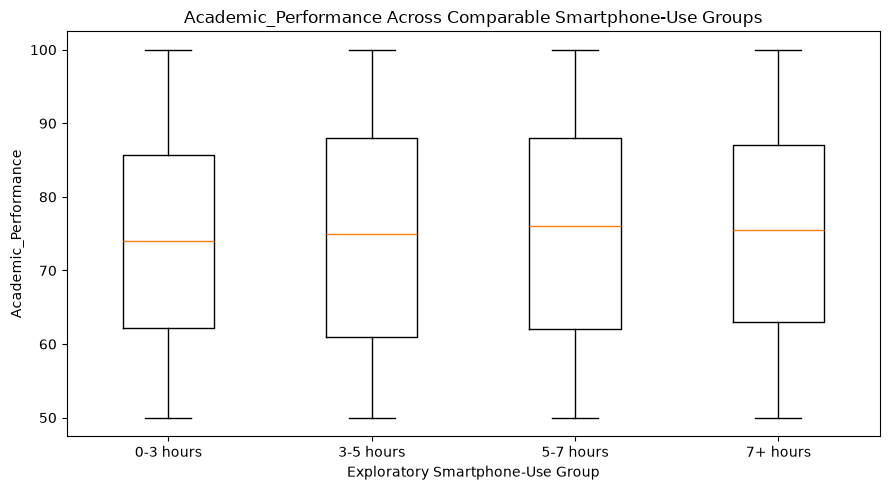

In [20]:
# Boxplots help visualize the spread of outcomes within each usage group

for outcome in group_outcomes:
    grouped_data = [
        df.loc[df["Usage_Group"] == group, outcome].dropna()
        for group in df["Usage_Group"].cat.categories
    ]

    plt.figure(figsize=(9, 5))

    plt.boxplot(
        grouped_data,
        tick_labels=[
            str(group)
            for group in df["Usage_Group"].cat.categories
        ]
    )

    plt.xlabel("Exploratory Smartphone-Use Group")
    plt.ylabel(outcome)
    plt.title(f"{outcome} Across Comparable Smartphone-Use Groups")

    plt.tight_layout()
    plt.show()


## 14. Optional: inspect a narrow smartphone-use range

This is a particularly useful exploratory step for your research question.

For example, the cell below isolates adolescents whose daily smartphone use is between **5.5 and 6.5 hours** and examines how much their outcomes vary even within that narrow exposure range.

You can change the bounds later.


In [21]:
lower_bound = 5.5
upper_bound = 6.5

similar_use = df[
    df["Daily_Usage_Hours"].between(lower_bound, upper_bound)
].copy()

print(
    f"Adolescents using smartphones between {lower_bound} and "
    f"{upper_bound} hours/day: {len(similar_use):,}"
)

display(
    similar_use[
        [
            "Daily_Usage_Hours",
            "Depression_Level",
            "Anxiety_Level",
            "Self_Esteem",
            "Sleep_Hours",
            "Academic_Performance"
        ]
    ].describe().T
)


Adolescents using smartphones between 5.5 and 6.5 hours/day: 538


,count,mean,std,min,25%,50%,75%,max
Daily_Usage_Hours,538.0,5.993123,0.311913,5.5,5.7,6.0,6.3,6.5
Depression_Level,538.0,5.600372,2.875790,1.0,3.0,6.0,8.0,10.0
Anxiety_Level,538.0,5.721190,2.825851,1.0,3.0,6.0,8.0,10.0
Self_Esteem,538.0,5.477695,2.833766,1.0,3.0,6.0,8.0,10.0
Sleep_Hours,538.0,6.507063,1.492884,3.0,5.4,6.5,7.5,10.0
Academic_Performance,538.0,74.985130,14.875641,50.0,62.0,74.5,88.0,100.0


In [22]:
def explore_relationship(x, y):
    plt.figure(figsize=(8, 5))

    plt.scatter(
        df[x],
        df[y],
        alpha=0.25
    )

    plt.xlabel(x)
    plt.ylabel(y)
    plt.title(f"{x} vs. {y}")

    plt.tight_layout()
    plt.show()

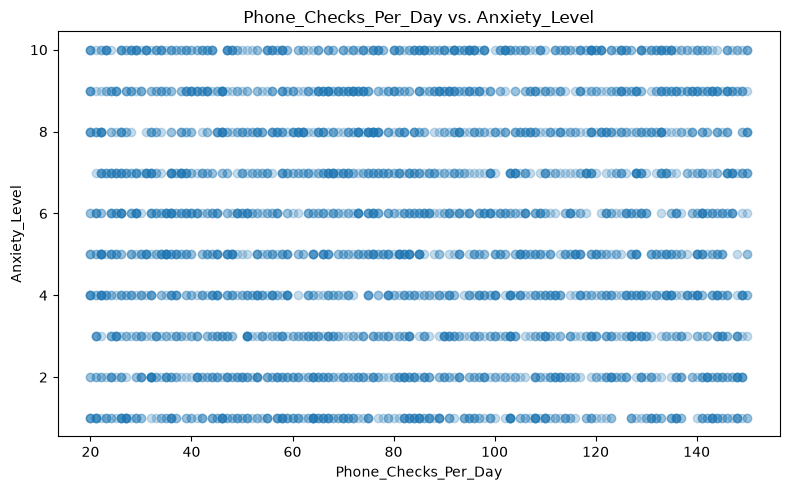

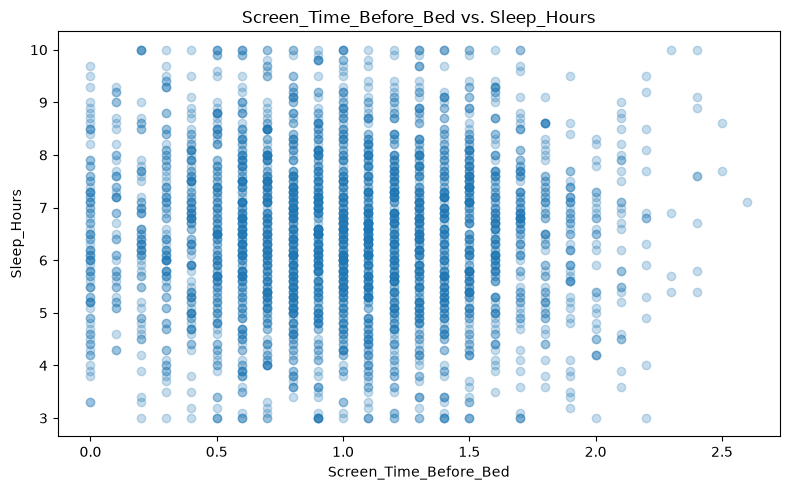

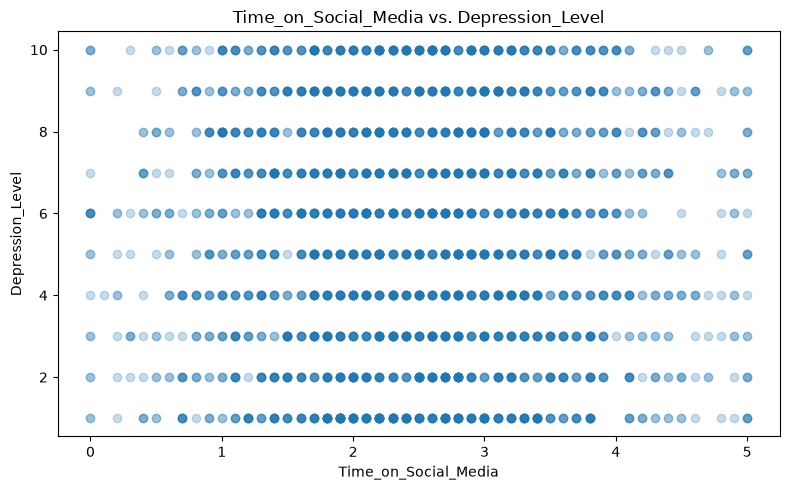

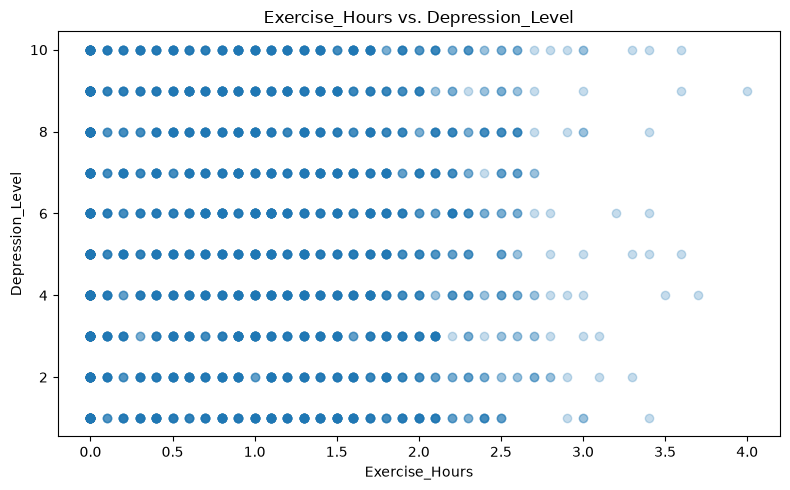

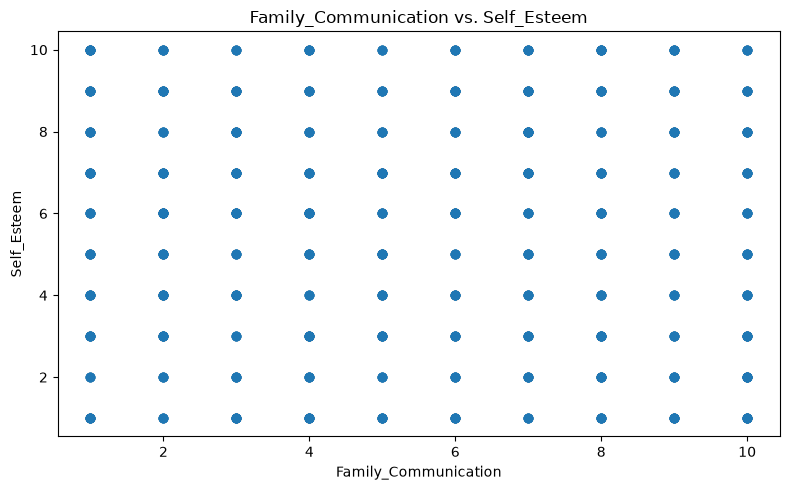

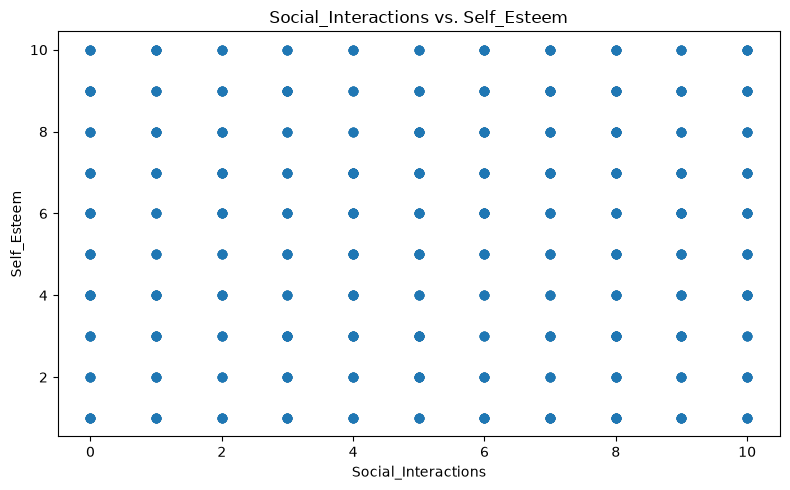

In [23]:
explore_relationship("Phone_Checks_Per_Day", "Anxiety_Level")

explore_relationship("Screen_Time_Before_Bed", "Sleep_Hours")

explore_relationship("Time_on_Social_Media", "Depression_Level")

explore_relationship("Exercise_Hours", "Depression_Level")

explore_relationship("Family_Communication", "Self_Esteem")

explore_relationship("Social_Interactions", "Self_Esteem")

### Why this matters
If there is substantial variation in well-being-related outcomes even within a narrow smartphone-exposure range, that gives you direct evidence that the next phase should investigate **which other factors distinguish those adolescents**.


## 15. EDA notes and observations

In [24]:
# ============================================================
# EDA NOTES
# ============================================================

# Dataset dimensions:
# _________________________________________________

# Missing values:
# _________________________________________________

# Duplicate rows / duplicate IDs:
# _________________________________________________

# Data-type issues:
# _________________________________________________

# Unusual ranges or possible outliers:
# 1.
# 2.
# 3.

# Important distribution observations:
# 1.
# 2.
# 3.

# Initial smartphone-exposure observations:
# 1.
# 2.
# 3.

# Evidence of variation in outcomes among adolescents
# with comparable smartphone exposure:
# 1.
# 2.
# 3.

# Strongest initial correlations:
# 1.
# 2.
# 3.

# Variables requiring further investigation:
# 1.
# 2.
# 3.

# Questions raised by the EDA:
# 1.
# 2.
# 3.


## 16. Next steps after this EDA

After reviewing and documenting the outputs above, the next phase can include:

1. Investigating questionable values and outliers.
2. Deciding which variables should represent well-being outcomes.
3. Determining the best way to define or control for **comparable smartphone exposure**.
4. Exploring feature engineering, such as:
   - phone checks per usage hour,
   - social-media share of total use,
   - gaming share of total use,
   - educational-use share,
   - weekend-use escalation,
   - bedtime-use intensity.
5. Testing whether behavioral, lifestyle, and psychosocial variables explain variation among adolescents with similar exposure.
6. Comparing simple statistical models with more advanced predictive models.

**Do not begin these steps until you have reviewed the initial EDA findings.**


## Well-Being Outcome Exploration

The research question focuses on differences in adolescent well-being among adolescents with comparable smartphone exposure.

The dataset does not contain a single variable labeled "well-being." Therefore, this section examines anxiety, depression, and self-esteem to determine whether they should be analyzed as separate outcomes or whether the data support representing them as a broader psychosocial well-being construct.

In [25]:
wellbeing_vars = [
    "Anxiety_Level",
    "Depression_Level",
    "Self_Esteem"
]

df[wellbeing_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
Anxiety_Level,3000.0,5.590000,2.890678,1.0,3.0,6.0,8.0,10.0
Depression_Level,3000.0,5.460333,2.871557,1.0,3.0,5.0,8.0,10.0
Self_Esteem,3000.0,5.546333,2.860754,1.0,3.0,6.0,8.0,10.0


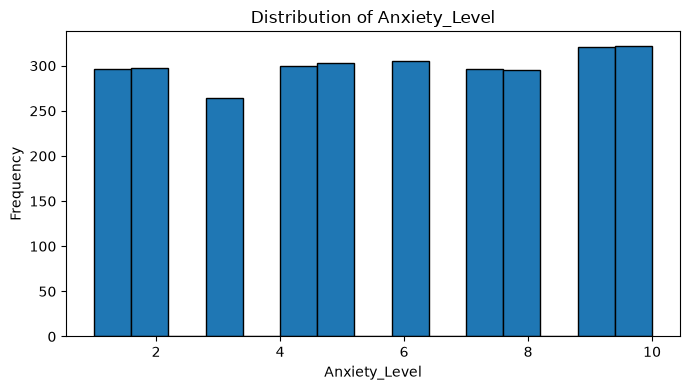

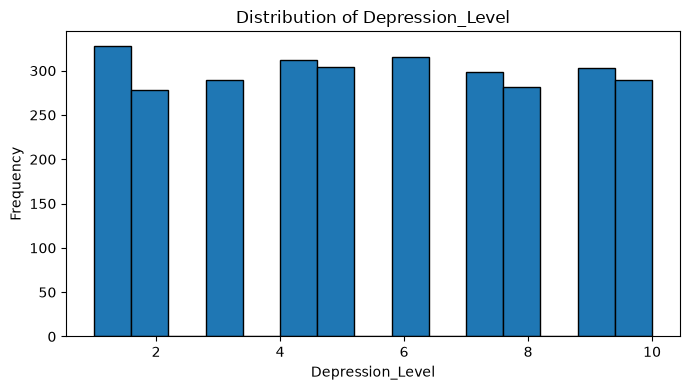

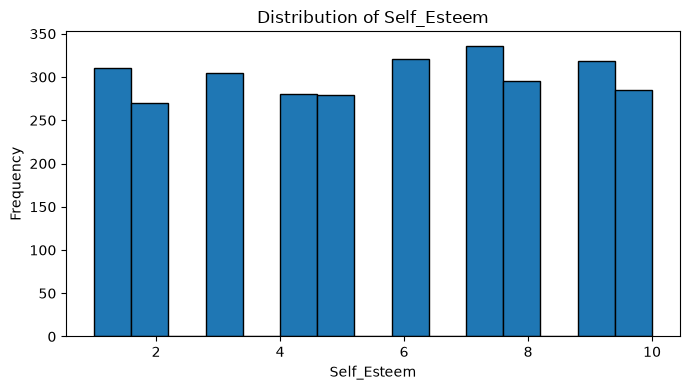

In [26]:
for variable in wellbeing_vars:

    plt.figure(figsize=(7, 4))

    plt.hist(
        df[variable],
        bins=15,
        edgecolor="black"
    )

    plt.xlabel(variable)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {variable}")

    plt.tight_layout()
    plt.show()

In [27]:
wellbeing_corr = df[wellbeing_vars].corr()

wellbeing_corr.round(3)

,Anxiety_Level,Depression_Level,Self_Esteem
Anxiety_Level,1.000,0.019,0.004
Depression_Level,0.019,1.000,-0.027
Self_Esteem,0.004,-0.027,1.000


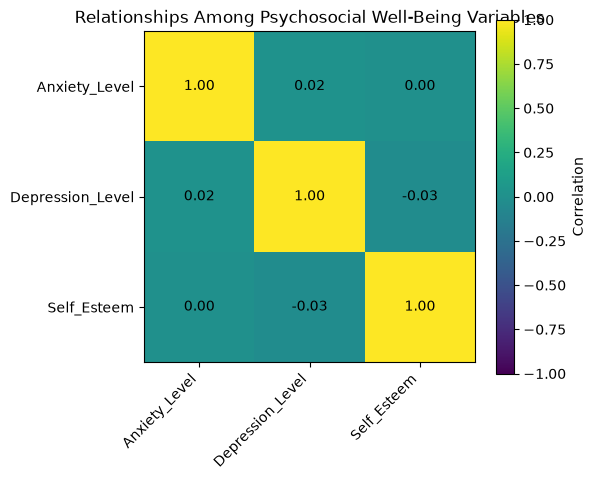

In [28]:
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(
    wellbeing_corr,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(wellbeing_vars)))
ax.set_yticks(range(len(wellbeing_vars)))

ax.set_xticklabels(
    wellbeing_vars,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(wellbeing_vars)

for i in range(len(wellbeing_vars)):
    for j in range(len(wellbeing_vars)):
        ax.text(
            j,
            i,
            f"{wellbeing_corr.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(im, label="Correlation")
plt.title("Relationships Among Psychosocial Well-Being Variables")

plt.tight_layout()
plt.show()

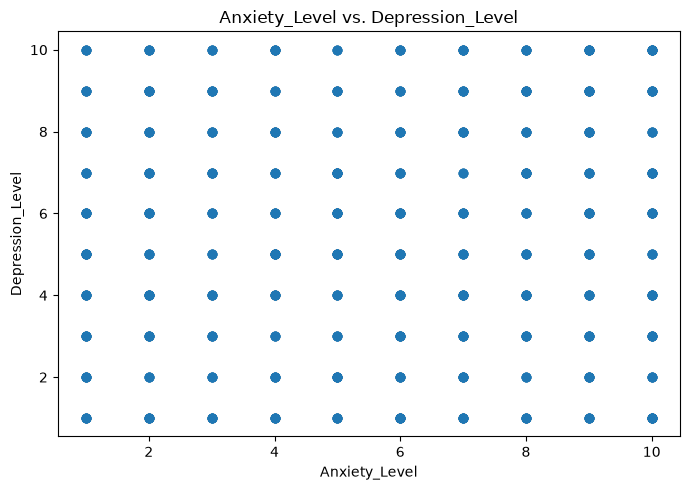

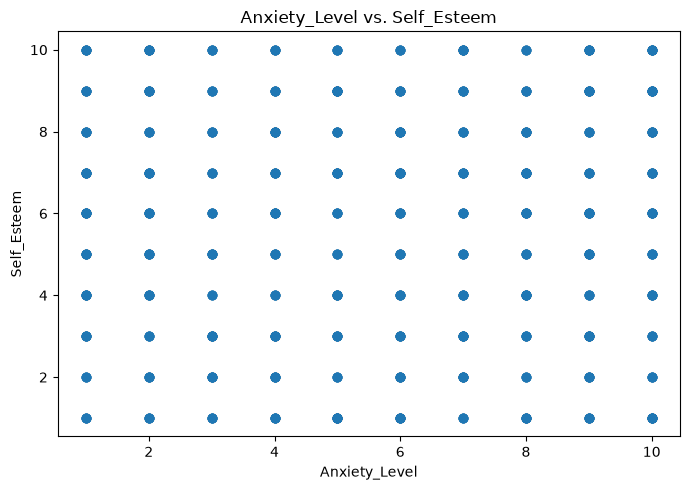

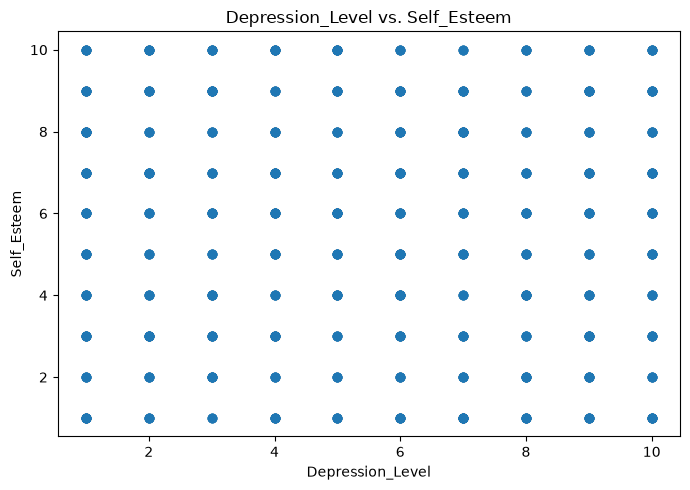

In [29]:
pairs = [
    ("Anxiety_Level", "Depression_Level"),
    ("Anxiety_Level", "Self_Esteem"),
    ("Depression_Level", "Self_Esteem")
]

for x, y in pairs:

    plt.figure(figsize=(7, 5))

    plt.scatter(
        df[x],
        df[y],
        alpha=0.25
    )

    plt.xlabel(x)
    plt.ylabel(y)
    plt.title(f"{x} vs. {y}")

    plt.tight_layout()
    plt.show()

In [30]:
exposure_outcomes = [
    "Daily_Usage_Hours",
    "Anxiety_Level",
    "Depression_Level",
    "Self_Esteem"
]

exposure_corr = (
    df[exposure_outcomes]
    .corr()["Daily_Usage_Hours"]
    .sort_values(ascending=False)
)

exposure_corr

Daily_Usage_Hours    1.000000
Depression_Level     0.009672
Self_Esteem          0.006340
Anxiety_Level       -0.007221
Name: Daily_Usage_Hours, dtype: float64

In [31]:
df[wellbeing_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
Anxiety_Level,3000.0,5.590000,2.890678,1.0,3.0,6.0,8.0,10.0
Depression_Level,3000.0,5.460333,2.871557,1.0,3.0,5.0,8.0,10.0
Self_Esteem,3000.0,5.546333,2.860754,1.0,3.0,6.0,8.0,10.0


In [32]:
wellbeing_corr.round(3)

,Anxiety_Level,Depression_Level,Self_Esteem
Anxiety_Level,1.000,0.019,0.004
Depression_Level,0.019,1.000,-0.027
Self_Esteem,0.004,-0.027,1.000


In [33]:
variable_roles = pd.DataFrame({
    "Variable": [
        "Anxiety_Level",
        "Depression_Level",
        "Self_Esteem",
        "Sleep_Hours",
        "Academic_Performance",
        "Phone_Checks_Per_Day",
        "Screen_Time_Before_Bed",
        "Time_on_Social_Media",
        "Time_on_Gaming",
        "Time_on_Education",
        "Apps_Used_Daily",
        "Weekend_Usage_Hours",
        "Phone_Usage_Purpose",
        "Exercise_Hours",
        "Social_Interactions",
        "Family_Communication",
        "Parental_Control",
        "Daily_Usage_Hours",
        "Age",
        "Gender",
        "School_Grade"
    ],

    "Role": [
        "Primary Outcome",
        "Primary Outcome",
        "Primary Outcome",
        "Secondary Outcome",
        "Secondary Outcome",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Lifestyle/Social Predictor",
        "Lifestyle/Social Predictor",
        "Lifestyle/Social Predictor",
        "Lifestyle/Social Predictor",
        "Exposure / Control",
        "Demographic / Control",
        "Demographic / Control",
        "Demographic / Control"
    ]
})

variable_roles

,Variable,Role
0,Anxiety_Level,Primary Outcome
1,Depression_Level,Primary Outcome
2,Self_Esteem,Primary Outcome
3,Sleep_Hours,Secondary Outcome
4,Academic_Performance,Secondary Outcome
5,Phone_Checks_Per_Day,Smartphone Behavior Predictor
6,Screen_Time_Before_Bed,Smartphone Behavior Predictor
7,Time_on_Social_Media,Smartphone Behavior Predictor
8,Time_on_Gaming,Smartphone Behavior Predictor
9,Time_on_Education,Smartphone Behavior Predictor


In [34]:
variable_roles = pd.DataFrame({
    "Variable": [
        "Anxiety_Level",
        "Depression_Level",
        "Self_Esteem",
        "Sleep_Hours",
        "Academic_Performance",
        "Phone_Checks_Per_Day",
        "Screen_Time_Before_Bed",
        "Time_on_Social_Media",
        "Time_on_Gaming",
        "Time_on_Education",
        "Apps_Used_Daily",
        "Weekend_Usage_Hours",
        "Phone_Usage_Purpose",
        "Exercise_Hours",
        "Social_Interactions",
        "Family_Communication",
        "Parental_Control",
        "Daily_Usage_Hours",
        "Age",
        "Gender",
        "School_Grade"
    ],
    
    "Role": [
        "Primary Outcome",
        "Primary Outcome",
        "Primary Outcome",
        "Secondary Outcome",
        "Secondary Outcome",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Smartphone Behavior Predictor",
        "Lifestyle/Social Predictor",
        "Lifestyle/Social Predictor",
        "Lifestyle/Social Predictor",
        "Lifestyle/Social Predictor",
        "Exposure / Control",
        "Demographic / Control",
        "Demographic / Control",
        "Demographic / Control"
    ],
    
    "Analysis_Status": [
        "Primary model outcome",
        "Primary model outcome",
        "Primary model outcome",
        "Secondary analysis",
        "Secondary analysis",
        "Candidate predictor",
        "Candidate predictor",
        "Candidate predictor",
        "Candidate predictor",
        "Candidate predictor",
        "Candidate predictor",
        "Candidate predictor",
        "Candidate predictor",
        "Candidate predictor",
        "Candidate predictor",
        "Candidate predictor",
        "Candidate predictor",
        "Core study variable",
        "Potential control",
        "Potential control",
        "Potential control"
    ]
})

variable_roles

,Variable,Role,Analysis_Status
0,Anxiety_Level,Primary Outcome,Primary model outcome
1,Depression_Level,Primary Outcome,Primary model outcome
2,Self_Esteem,Primary Outcome,Primary model outcome
3,Sleep_Hours,Secondary Outcome,Secondary analysis
4,Academic_Performance,Secondary Outcome,Secondary analysis
5,Phone_Checks_Per_Day,Smartphone Behavior Predictor,Candidate predictor
6,Screen_Time_Before_Bed,Smartphone Behavior Predictor,Candidate predictor
7,Time_on_Social_Media,Smartphone Behavior Predictor,Candidate predictor
8,Time_on_Gaming,Smartphone Behavior Predictor,Candidate predictor
9,Time_on_Education,Smartphone Behavior Predictor,Candidate predictor


## Study Variable Framework

Well-being is treated as a multidimensional construct rather than a single composite score. Anxiety, depression, and self-esteem are retained as separate primary outcomes because preliminary EDA showed that they are only weakly correlated in this dataset.

Sleep and academic performance are retained as secondary outcomes representing restorative/health and functional dimensions.

Daily smartphone usage is treated as the primary exposure variable rather than an ordinary predictor. The central analysis will examine which smartphone behaviors, lifestyle factors, and social/contextual factors distinguish outcomes among adolescents with comparable levels of total smartphone exposure.

Demographic variables may be included as control variables where appropriate.

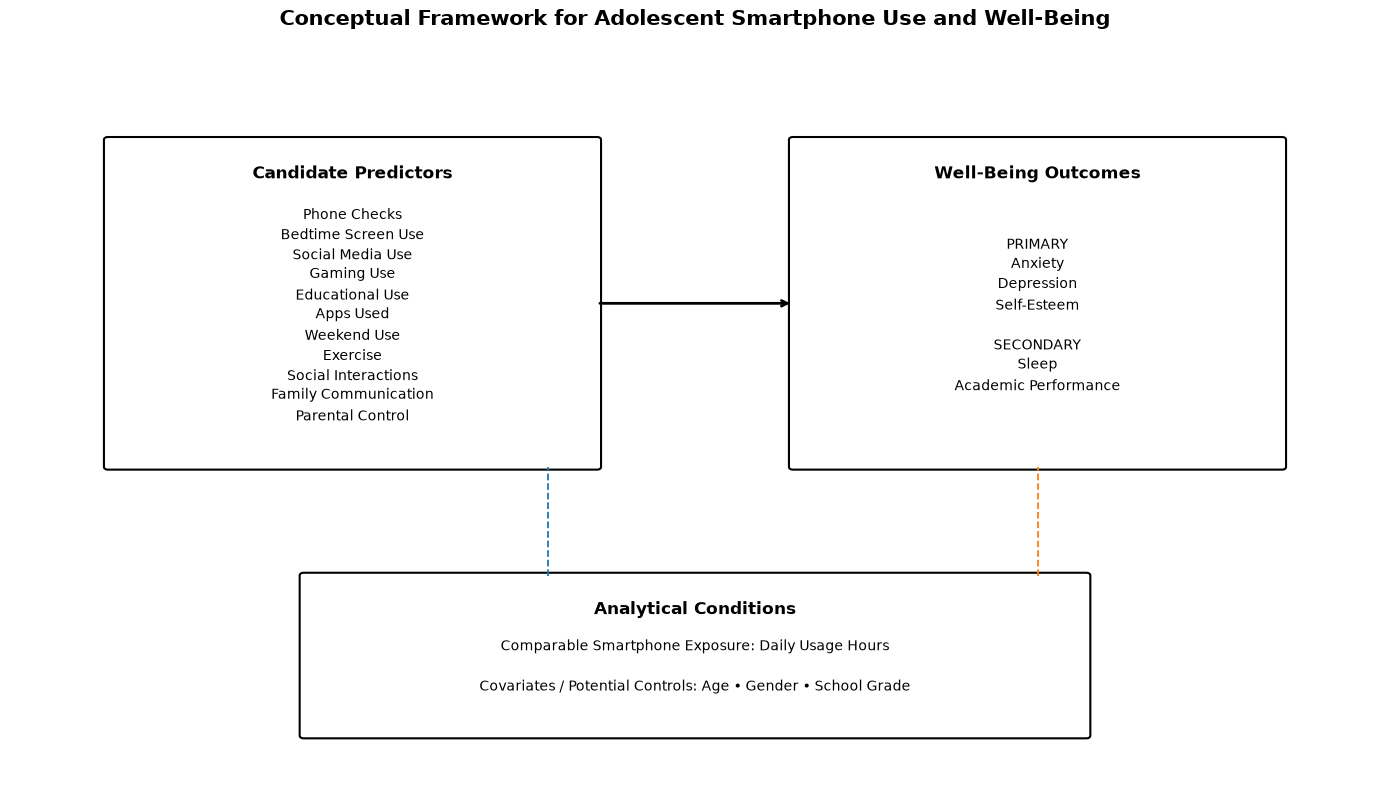

In [35]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 8))

ax.set_xlim(0, 14)
ax.set_ylim(0, 10)
ax.axis("off")


# ---------------------------------------------------------
# Helper function
# ---------------------------------------------------------

def add_box(x, y, width, height, title, text):
    
    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.04",
        linewidth=1.5,
        fill=False
    )
    
    ax.add_patch(box)

    # Title
    ax.text(
        x + width / 2,
        y + height - 0.35,
        title,
        ha="center",
        va="top",
        fontsize=12,
        fontweight="bold"
    )

    # Contents
    ax.text(
        x + width / 2,
        y + height / 2 - 0.15,
        text,
        ha="center",
        va="center",
        fontsize=10,
        linespacing=1.45
    )


# ---------------------------------------------------------
# Main predictor box
# ---------------------------------------------------------

add_box(
    1, 4.3, 5, 4.5,
    "Candidate Predictors",
    "Phone Checks\n"
    "Bedtime Screen Use\n"
    "Social Media Use\n"
    "Gaming Use\n"
    "Educational Use\n"
    "Apps Used\n"
    "Weekend Use\n"
    "Exercise\n"
    "Social Interactions\n"
    "Family Communication\n"
    "Parental Control"
)


# ---------------------------------------------------------
# Well-being outcomes
# ---------------------------------------------------------

add_box(
    8, 4.3, 5, 4.5,
    "Well-Being Outcomes",
    "PRIMARY\n"
    "Anxiety\n"
    "Depression\n"
    "Self-Esteem\n\n"
    "SECONDARY\n"
    "Sleep\n"
    "Academic Performance"
)


# ---------------------------------------------------------
# Main relationship
# ---------------------------------------------------------

ax.annotate(
    "",
    xy=(8, 6.55),
    xytext=(6, 6.55),
    arrowprops=dict(
        arrowstyle="->",
        linewidth=2
    )
)


# ---------------------------------------------------------
# Analytical conditions
# ---------------------------------------------------------

add_box(
    3, 0.6, 8, 2.2,
    "Analytical Conditions",
    "Comparable Smartphone Exposure: Daily Usage Hours\n\n"
    "Covariates / Potential Controls: Age • Gender • School Grade"
)


# Dashed lines indicate adjustment/conditioning rather than
# hypothesized causal relationships

ax.plot(
    [5.5, 5.5],
    [2.8, 4.3],
    linestyle="--",
    linewidth=1.3
)

ax.plot(
    [10.5, 10.5],
    [2.8, 4.3],
    linestyle="--",
    linewidth=1.3
)


# ---------------------------------------------------------
# Title
# ---------------------------------------------------------

plt.title(
    "Conceptual Framework for Adolescent Smartphone Use and Well-Being",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.show()

## Predictor–Outcome Screening

The following analysis examines relationships between candidate predictors and the three primary psychosocial well-being outcomes: anxiety, depression, and self-esteem.

This is an exploratory screening step intended to identify patterns for further investigation. Correlation coefficients are used to describe the direction and magnitude of relationships, while p-values provide additional information about statistical evidence.

These results are not interpreted as causal effects and do not yet account for comparable levels of total smartphone exposure or potential demographic covariates.

In [36]:
screening_predictors = [
    "Phone_Checks_Per_Day",
    "Screen_Time_Before_Bed",
    "Time_on_Social_Media",
    "Time_on_Gaming",
    "Time_on_Education",
    "Apps_Used_Daily",
    "Weekend_Usage_Hours",
    "Exercise_Hours",
    "Social_Interactions",
    "Family_Communication",
    "Parental_Control"
]

primary_outcomes = [
    "Anxiety_Level",
    "Depression_Level",
    "Self_Esteem"
]

In [37]:
from scipy.stats import pearsonr

screening_results = []

for predictor in screening_predictors:
    
    for outcome in primary_outcomes:
        
        # Keep only complete observations for this pair
        pair_data = df[[predictor, outcome]].dropna()
        
        r, p = pearsonr(
            pair_data[predictor],
            pair_data[outcome]
        )
        
        screening_results.append({
            "Predictor": predictor,
            "Outcome": outcome,
            "Correlation": r,
            "P_Value": p
        })

screening_df = pd.DataFrame(screening_results)

screening_df.head()

,Predictor,Outcome,Correlation,P_Value
0,Phone_Checks_Per_Day,Anxiety_Level,0.017988,0.324659
1,Phone_Checks_Per_Day,Depression_Level,-0.001146,0.949984
2,Phone_Checks_Per_Day,Self_Esteem,-0.005905,0.746455
3,Screen_Time_Before_Bed,Anxiety_Level,-0.004732,0.795587
4,Screen_Time_Before_Bed,Depression_Level,-0.028389,0.120044


In [38]:
def correlation_strength(r):
    
    abs_r = abs(r)
    
    if abs_r < 0.10:
        return "Very weak"
    elif abs_r < 0.30:
        return "Weak"
    elif abs_r < 0.50:
        return "Moderate"
    else:
        return "Strong"


screening_df["Strength"] = (
    screening_df["Correlation"]
    .apply(correlation_strength)
)

screening_df["Significant"] = np.where(
    screening_df["P_Value"] < 0.05,
    "Yes",
    "No"
)

screening_df["Correlation"] = screening_df["Correlation"].round(3)
screening_df["P_Value"] = screening_df["P_Value"].round(4)

screening_df

,Predictor,Outcome,Correlation,P_Value,Strength,Significant
0,Phone_Checks_Per_Day,Anxiety_Level,0.018,0.3247,Very weak,No
1,Phone_Checks_Per_Day,Depression_Level,-0.001,0.9500,Very weak,No
2,Phone_Checks_Per_Day,Self_Esteem,-0.006,0.7465,Very weak,No
3,Screen_Time_Before_Bed,Anxiety_Level,-0.005,0.7956,Very weak,No
4,Screen_Time_Before_Bed,Depression_Level,-0.028,0.1200,Very weak,No
5,Screen_Time_Before_Bed,Self_Esteem,0.004,0.8454,Very weak,No
6,Time_on_Social_Media,Anxiety_Level,-0.003,0.8809,Very weak,No
7,Time_on_Social_Media,Depression_Level,0.002,0.9233,Very weak,No
8,Time_on_Social_Media,Self_Esteem,-0.009,0.6193,Very weak,No
9,Time_on_Gaming,Anxiety_Level,0.015,0.4216,Very weak,No


In [39]:
correlation_matrix = screening_df.pivot(
    index="Predictor",
    columns="Outcome",
    values="Correlation"
)

correlation_matrix = correlation_matrix[
    [
        "Anxiety_Level",
        "Depression_Level",
        "Self_Esteem"
    ]
]

correlation_matrix

Outcome,Anxiety_Level,Depression_Level,Self_Esteem
Predictor,,,
Apps_Used_Daily,0.007,0.019,-0.027
Exercise_Hours,0.005,-0.012,-0.014
Family_Communication,0.011,-0.013,-0.026
Parental_Control,-0.012,0.015,-0.028
Phone_Checks_Per_Day,0.018,-0.001,-0.006
Screen_Time_Before_Bed,-0.005,-0.028,0.004
Social_Interactions,0.004,0.024,0.008
Time_on_Education,0.025,-0.029,-0.009
Time_on_Gaming,0.015,-0.009,-0.008


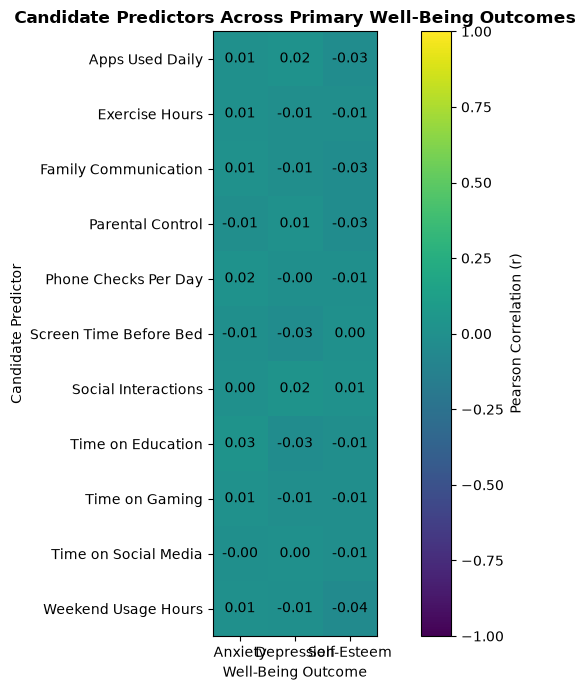

In [40]:
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    correlation_matrix.values,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.index)))

ax.set_xticklabels(
    [
        "Anxiety",
        "Depression",
        "Self-Esteem"
    ]
)

ax.set_yticklabels(
    [
        label.replace("_", " ")
        for label in correlation_matrix.index
    ]
)

for i in range(len(correlation_matrix.index)):
    for j in range(len(correlation_matrix.columns)):
        
        value = correlation_matrix.iloc[i, j]
        
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(
    im,
    label="Pearson Correlation (r)"
)

plt.title(
    "Candidate Predictors Across Primary Well-Being Outcomes",
    fontweight="bold"
)

plt.xlabel("Well-Being Outcome")
plt.ylabel("Candidate Predictor")

plt.tight_layout()
plt.show()

In [41]:
ranked_relationships = (
    screening_df
    .assign(
        Absolute_Correlation=lambda x:
        x["Correlation"].abs()
    )
    .sort_values(
        "Absolute_Correlation",
        ascending=False
    )
)

ranked_relationships[
    [
        "Predictor",
        "Outcome",
        "Correlation",
        "P_Value",
        "Strength",
        "Significant"
    ]
].head(15)

,Predictor,Outcome,Correlation,P_Value,Strength,Significant
20,Weekend_Usage_Hours,Self_Esteem,-0.041,0.0259,Very weak,Yes
13,Time_on_Education,Depression_Level,-0.029,0.1171,Very weak,No
32,Parental_Control,Self_Esteem,-0.028,0.1240,Very weak,No
4,Screen_Time_Before_Bed,Depression_Level,-0.028,0.1200,Very weak,No
17,Apps_Used_Daily,Self_Esteem,-0.027,0.1333,Very weak,No
29,Family_Communication,Self_Esteem,-0.026,0.1530,Very weak,No
12,Time_on_Education,Anxiety_Level,0.025,0.1773,Very weak,No
25,Social_Interactions,Depression_Level,0.024,0.1852,Very weak,No
16,Apps_Used_Daily,Depression_Level,0.019,0.2969,Very weak,No
0,Phone_Checks_Per_Day,Anxiety_Level,0.018,0.3247,Very weak,No


In [42]:
numeric_df = df.select_dtypes(include="number")

full_corr = numeric_df.corr()

full_corr.round(2)

,ID,Age,Daily_Usage_Hours,Sleep_Hours,Academic_Performance,Social_Interactions,Exercise_Hours,Anxiety_Level,Depression_Level,Self_Esteem,Parental_Control,Screen_Time_Before_Bed,Phone_Checks_Per_Day,Apps_Used_Daily,Time_on_Social_Media,Time_on_Gaming,Time_on_Education,Family_Communication,Weekend_Usage_Hours,Addiction_Level
ID,1.00,-0.04,-0.00,0.02,-0.01,-0.04,0.00,0.01,0.00,-0.01,-0.02,0.00,-0.04,-0.00,0.02,0.01,-0.00,-0.02,0.02,-0.01
Age,-0.04,1.00,0.04,0.01,0.02,-0.02,0.00,0.01,0.05,-0.03,0.03,0.01,-0.01,-0.00,-0.01,-0.01,0.01,-0.00,0.00,0.03
Daily_Usage_Hours,-0.00,0.04,1.00,0.02,0.02,-0.03,-0.01,-0.01,0.01,0.01,0.00,0.00,0.00,0.02,-0.01,-0.01,0.01,0.00,0.02,0.60
Sleep_Hours,0.02,0.01,0.02,1.00,-0.00,-0.02,0.01,0.01,-0.01,0.02,0.01,-0.00,0.01,0.03,-0.02,0.01,-0.01,-0.03,-0.00,-0.22
Academic_Performance,-0.01,0.02,0.02,-0.00,1.00,0.01,-0.00,0.00,-0.03,-0.01,0.00,-0.01,-0.02,-0.03,0.04,-0.03,0.02,-0.03,0.01,0.01
Social_Interactions,-0.04,-0.02,-0.03,-0.02,0.01,1.00,0.01,0.00,0.02,0.01,-0.02,-0.02,0.01,-0.03,0.00,-0.00,-0.01,0.00,-0.02,-0.01
Exercise_Hours,0.00,0.00,-0.01,0.01,-0.00,0.01,1.00,0.00,-0.01,-0.01,0.02,0.02,-0.01,-0.01,-0.02,-0.01,0.02,0.01,0.04,-0.02
Anxiety_Level,0.01,0.01,-0.01,0.01,0.00,0.00,0.00,1.00,0.02,0.00,-0.01,-0.00,0.02,0.01,-0.00,0.01,0.02,0.01,0.01,0.02
Depression_Level,0.00,0.05,0.01,-0.01,-0.03,0.02,-0.01,0.02,1.00,-0.03,0.01,-0.03,-0.00,0.02,0.00,-0.01,-0.03,-0.01,-0.01,0.01
Self_Esteem,-0.01,-0.03,0.01,0.02,-0.01,0.01,-0.01,0.00,-0.03,1.00,-0.03,0.00,-0.01,-0.03,-0.01,-0.01,-0.01,-0.03,-0.04,-0.02


In [43]:
corr_pairs = (
    full_corr
    .where(
        np.triu(
            np.ones(full_corr.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Variable_1",
    "Variable_2",
    "Correlation"
]

corr_pairs["Absolute_Correlation"] = (
    corr_pairs["Correlation"].abs()
)

strongest_dataset_relationships = (
    corr_pairs
    .sort_values(
        "Absolute_Correlation",
        ascending=False
    )
)

strongest_dataset_relationships.head(20)

,Variable_1,Variable_2,Correlation,Absolute_Correlation
59,Daily_Usage_Hours,Addiction_Level,0.600771,0.600771
279,Apps_Used_Daily,Addiction_Level,0.319287,0.319287
299,Time_on_Social_Media,Addiction_Level,0.306578,0.306578
319,Time_on_Gaming,Addiction_Level,0.273060,0.273060
259,Phone_Checks_Per_Day,Addiction_Level,0.246342,0.246342
79,Sleep_Hours,Addiction_Level,-0.216681,0.216681
28,Age,Depression_Level,0.052699,0.052699
238,Screen_Time_Before_Bed,Weekend_Usage_Hours,0.041958,0.041958
5,ID,Social_Interactions,-0.041130,0.041130
22,Age,Daily_Usage_Hours,0.040689,0.040689


In [44]:
# Compare correlation structure with and without Addiction_Level

corr_without_addiction = (
    corr_pairs[
        (corr_pairs["Variable_1"] != "Addiction_Level") &
        (corr_pairs["Variable_2"] != "Addiction_Level") &
        (corr_pairs["Variable_1"] != "ID") &
        (corr_pairs["Variable_2"] != "ID")
    ]
    .sort_values(
        "Absolute_Correlation",
        ascending=False
    )
)

corr_without_addiction.head(20)

,Variable_1,Variable_2,Correlation,Absolute_Correlation
28,Age,Depression_Level,0.052699,0.052699
238,Screen_Time_Before_Bed,Weekend_Usage_Hours,0.041958,0.041958
22,Age,Daily_Usage_Hours,0.040689,0.040689
198,Self_Esteem,Weekend_Usage_Hours,-0.040673,0.040673
138,Exercise_Hours,Weekend_Usage_Hours,0.039873,0.039873
212,Parental_Control,Phone_Checks_Per_Day,0.037019,0.037019
94,Academic_Performance,Time_on_Social_Media,0.036357,0.036357
95,Academic_Performance,Time_on_Gaming,-0.033734,0.033734
211,Parental_Control,Screen_Time_Before_Bed,-0.033619,0.033619
29,Age,Self_Esteem,-0.033177,0.033177


In [45]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [46]:
import statsmodels.api as sm

features = [
    "Daily_Usage_Hours",
    "Screen_Time_Before_Bed",
    "Exercise_Hours",
    "Social_Interactions",
    "Family_Communication"
]

X = df[features]
y = df["Depression_Level"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       Depression_Level   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.058
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.382
Time:                        19:29:49   Log-Likelihood:                -7418.2
No. Observations:                3000   AIC:                         1.485e+04
Df Residuals:                    2994   BIC:                         1.488e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      5

In [47]:
outcomes = [
    "Depression_Level",
    "Anxiety_Level",
    "Self_Esteem"
]

features = [
    "Daily_Usage_Hours",
    "Screen_Time_Before_Bed",
    "Exercise_Hours",
    "Social_Interactions",
    "Family_Communication"
]

X = df[features]
X = sm.add_constant(X)

for outcome in outcomes:
    y = df[outcome]
    model = sm.OLS(y, X).fit()

In [48]:
import statsmodels.api as sm

features = [
    "Daily_Usage_Hours",
    "Screen_Time_Before_Bed",
    "Exercise_Hours",
    "Social_Interactions",
    "Family_Communication"
]

X = df[features]
X = sm.add_constant(X)

# Model 1: Depression
depression_model = sm.OLS(
    df["Depression_Level"], X
).fit()

# Model 2: Anxiety
anxiety_model = sm.OLS(
    df["Anxiety_Level"], X
).fit()

# Model 3: Self-Esteem
self_esteem_model = sm.OLS(
    df["Self_Esteem"], X
).fit()

In [49]:
print(anxiety_model.summary())

                            OLS Regression Results                            
Dep. Variable:          Anxiety_Level   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.1406
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.983
Time:                        19:29:50   Log-Likelihood:                -7440.4
No. Observations:                3000   AIC:                         1.489e+04
Df Residuals:                    2994   BIC:                         1.493e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      5

In [50]:
print(self_esteem_model.summary())

                            OLS Regression Results                            
Dep. Variable:            Self_Esteem   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.6086
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.693
Time:                        19:29:50   Log-Likelihood:                -7408.0
No. Observations:                3000   AIC:                         1.483e+04
Df Residuals:                    2994   BIC:                         1.486e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      5

In [51]:
print(df.columns.tolist())

['ID', 'Name', 'Age', 'Gender', 'Location', 'School_Grade', 'Daily_Usage_Hours', 'Sleep_Hours', 'Academic_Performance', 'Social_Interactions', 'Exercise_Hours', 'Anxiety_Level', 'Depression_Level', 'Self_Esteem', 'Parental_Control', 'Screen_Time_Before_Bed', 'Phone_Checks_Per_Day', 'Apps_Used_Daily', 'Time_on_Social_Media', 'Time_on_Gaming', 'Time_on_Education', 'Phone_Usage_Purpose', 'Family_Communication', 'Weekend_Usage_Hours', 'Addiction_Level', 'Usage_Group']


In [52]:
numeric_features = [
    "Age",
    "Daily_Usage_Hours",
    "Sleep_Hours",
    "Academic_Performance",
    "Social_Interactions",
    "Exercise_Hours",
    "Screen_Time_Before_Bed",
    "Phone_Checks_Per_Day",
    "Apps_Used_Daily",
    "Time_on_Social_Media",
    "Time_on_Gaming",
    "Time_on_Education",
    "Family_Communication",
    "Weekend_Usage_Hours"
]

outcomes = [
    "Anxiety_Level",
    "Depression_Level",
    "Self_Esteem"
]

correlations = df[numeric_features + outcomes].corr()

feature_correlations = correlations.loc[numeric_features, outcomes]

feature_correlations

,Anxiety_Level,Depression_Level,Self_Esteem
Age,0.014651,0.052699,-0.033177
Daily_Usage_Hours,-0.007221,0.009672,0.006340
Sleep_Hours,0.009836,-0.011518,0.016488
Academic_Performance,0.003427,-0.026509,-0.005459
Social_Interactions,0.004341,0.024195,0.008314
Exercise_Hours,0.004525,-0.011770,-0.014320
Screen_Time_Before_Bed,-0.004732,-0.028389,0.003562
Phone_Checks_Per_Day,0.017988,-0.001146,-0.005905
Apps_Used_Daily,0.007416,0.019049,-0.027416
Time_on_Social_Media,-0.002736,0.001758,-0.009075


In [53]:
features = [
    "Sleep_Hours",
    "Academic_Performance",
    "Social_Interactions",
    "Exercise_Hours",
    "Screen_Time_Before_Bed",
    "Phone_Checks_Per_Day",
    "Apps_Used_Daily",
    "Time_on_Social_Media",
    "Time_on_Gaming",
    "Time_on_Education",
    "Family_Communication",
    "Weekend_Usage_Hours"
]

outcomes = [
    "Anxiety_Level",
    "Depression_Level",
    "Self_Esteem"
]

for group in df["Usage_Group"].cat.categories:
    
    subset = df[df["Usage_Group"] == group]
    
    corr = subset[features + outcomes].corr()
    
    print("\n" + "=" * 70)
    print(f"USAGE GROUP: {group} (n={len(subset)})")
    print("=" * 70)
    
    display(
        corr.loc[features, outcomes]
        .round(3)
    )


USAGE GROUP: 0-3 hours (n=470)


,Anxiety_Level,Depression_Level,Self_Esteem
Sleep_Hours,-0.026,-0.128,0.015
Academic_Performance,0.100,-0.036,0.007
Social_Interactions,-0.053,0.045,0.018
Exercise_Hours,-0.060,-0.079,-0.054
Screen_Time_Before_Bed,-0.015,-0.072,0.007
Phone_Checks_Per_Day,-0.004,0.030,-0.012
Apps_Used_Daily,-0.023,-0.011,-0.054
Time_on_Social_Media,0.003,-0.026,-0.032
Time_on_Gaming,-0.012,0.008,-0.072
Time_on_Education,0.076,-0.033,0.027



USAGE GROUP: 3-5 hours (n=1075)


,Anxiety_Level,Depression_Level,Self_Esteem
Sleep_Hours,0.026,0.016,0.026
Academic_Performance,-0.014,-0.064,0.019
Social_Interactions,0.010,0.027,0.011
Exercise_Hours,0.039,-0.018,-0.033
Screen_Time_Before_Bed,-0.019,-0.001,0.012
Phone_Checks_Per_Day,0.028,0.019,0.011
Apps_Used_Daily,0.055,0.039,-0.002
Time_on_Social_Media,-0.022,-0.007,-0.016
Time_on_Gaming,0.067,-0.022,-0.034
Time_on_Education,0.025,-0.023,-0.018



USAGE GROUP: 5-7 hours (n=1001)


,Anxiety_Level,Depression_Level,Self_Esteem
Sleep_Hours,0.029,0.047,0.015
Academic_Performance,0.001,0.039,-0.014
Social_Interactions,0.023,0.021,-0.014
Exercise_Hours,0.008,-0.004,-0.016
Screen_Time_Before_Bed,0.015,-0.033,-0.020
Phone_Checks_Per_Day,0.018,-0.027,-0.009
Apps_Used_Daily,-0.019,0.012,-0.044
Time_on_Social_Media,0.016,0.001,-0.001
Time_on_Gaming,-0.032,-0.006,0.013
Time_on_Education,0.029,-0.007,-0.040



USAGE GROUP: 7+ hours (n=454)


,Anxiety_Level,Depression_Level,Self_Esteem
Sleep_Hours,-0.035,-0.094,-0.001
Academic_Performance,-0.044,-0.075,-0.061
Social_Interactions,0.006,0.005,0.040
Exercise_Hours,-0.023,0.050,0.078
Screen_Time_Before_Bed,-0.005,-0.038,0.033
Phone_Checks_Per_Day,0.018,-0.029,-0.031
Apps_Used_Daily,-0.019,0.020,-0.030
Time_on_Social_Media,-0.002,0.047,0.014
Time_on_Gaming,0.031,-0.010,0.088
Time_on_Education,-0.037,-0.079,0.037


# Revised Research Question and Classification Analysis

## Research Question
What behavioral, lifestyle, and demographic factors distinguish adolescents 
with low, moderate, and high levels of daily smartphone use?

## Rationale for Revision
Preliminary EDA and baseline regression modeling showed very weak relationships 
between the available predictors and the original well-being outcomes. Based on 
these findings, the research question was refined to better align the analysis 
with patterns observed in the data.

,Count,Percentage
Usage_Group,,
Low,916,30.53
Moderate,1168,38.93
High,916,30.53


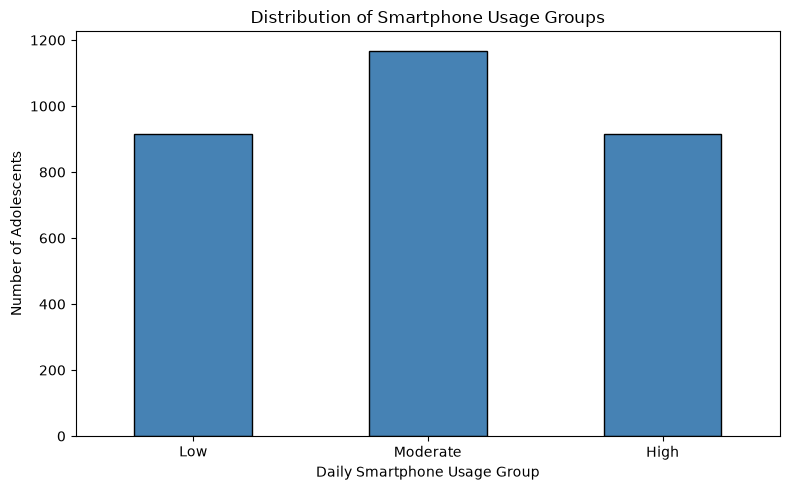

In [54]:

# Define the target variable for the revised research question

df["Usage_Group"] = pd.cut(
    df["Daily_Usage_Hours"],
    bins=[-float("inf"), 4, 6, float("inf")],
    labels=["Low", "Moderate", "High"]
)

# Check class distribution
usage_distribution = pd.DataFrame({
    "Count": df["Usage_Group"].value_counts().sort_index(),
    "Percentage": (
        df["Usage_Group"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
})

display(usage_distribution)

# Visualize distribution
plt.figure(figsize=(8, 5))

usage_distribution["Count"].plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of Smartphone Usage Groups")
plt.xlabel("Daily Smartphone Usage Group")
plt.ylabel("Number of Adolescents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [55]:

# Screen potential predictors

# Exclude identifiers, target, and potential leakage variables
exclude_cols = [
    "ID",
    "Name",
    "Daily_Usage_Hours",
    "Usage_Group",
    "Addiction_Level",
    "Weekend_Usage_Hours"
]

# Identify remaining predictors
predictor_cols = [
    col for col in df.columns
    if col not in exclude_cols
]

# Review predictor information
predictor_summary = pd.DataFrame({
    "Data_Type": df[predictor_cols].dtypes.astype(str),
    "Missing_Values": df[predictor_cols].isnull().sum(),
    "Unique_Values": df[predictor_cols].nunique()
})

display(predictor_summary)

,Data_Type,Missing_Values,Unique_Values
Age,int64,0,7
Gender,str,0,3
Location,str,0,2726
School_Grade,str,0,6
Sleep_Hours,float64,0,71
Academic_Performance,int64,0,51
Social_Interactions,int64,0,11
Exercise_Hours,float64,0,39
Anxiety_Level,int64,0,10
Depression_Level,int64,0,10


In [56]:

from sklearn.model_selection import train_test_split

# Final predictor selection
exclude_cols = [
    "ID",
    "Name",
    "Location",
    "Daily_Usage_Hours",
    "Usage_Group",
    "Addiction_Level",
    "Weekend_Usage_Hours"
]

# Create feature matrix and target
X = df.drop(columns=exclude_cols, errors="ignore")
y = df["Usage_Group"]

# Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining group distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting group distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training observations: 2400
Testing observations: 600

Training group distribution:
Usage_Group
Low         0.305
Moderate    0.389
High        0.305
Name: proportion, dtype: float64

Testing group distribution:
Usage_Group
Low         0.305
Moderate    0.390
High        0.305
Name: proportion, dtype: float64


In [57]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import pandas as pd

# Identify numeric and categorical predictors
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Define three models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

# Train and evaluate
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro_F1": f1_score(
            y_test, y_pred, average="macro"
        )
    })

    print(f"\n{name}")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

# Compare model performance
results_df = pd.DataFrame(results).sort_values(
    by="Macro_F1",
    ascending=False
)

display(results_df.round(3))


Logistic Regression
              precision    recall  f1-score   support

        High       0.28      0.09      0.14       183
         Low       0.27      0.16      0.20       183
    Moderate       0.37      0.68      0.48       234

    accuracy                           0.34       600
   macro avg       0.31      0.31      0.28       600
weighted avg       0.31      0.34      0.29       600


Decision Tree
              precision    recall  f1-score   support

        High       0.18      0.01      0.02       183
         Low       0.31      0.46      0.37       183
    Moderate       0.38      0.51      0.43       234

    accuracy                           0.34       600
   macro avg       0.29      0.33      0.28       600
weighted avg       0.30      0.34      0.29       600


Random Forest
              precision    recall  f1-score   support

        High       0.34      0.19      0.24       183
         Low       0.34      0.19      0.25       183
    Moderate       0.38 

,Model,Accuracy,Macro_F1
2,Random Forest,0.367,0.321
0,Logistic Regression,0.345,0.276
1,Decision Tree,0.343,0.275


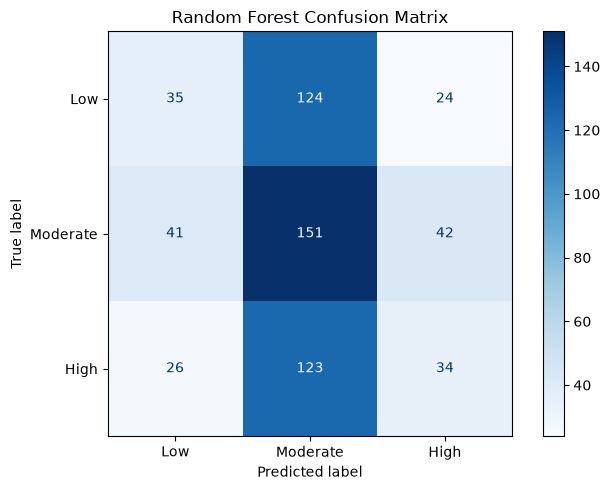

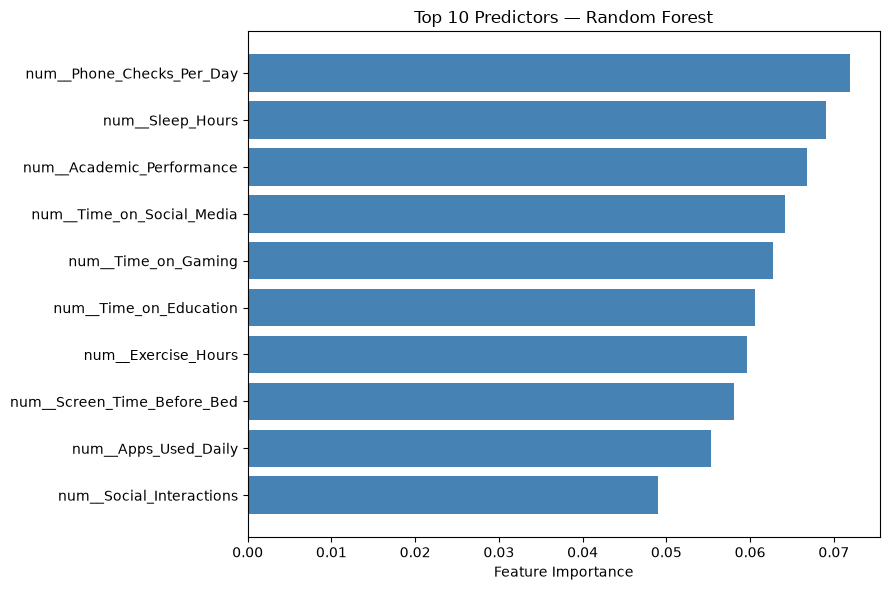

,Feature,Importance
10,num__Phone_Checks_Per_Day,0.071916
1,num__Sleep_Hours,0.069029
2,num__Academic_Performance,0.066754
12,num__Time_on_Social_Media,0.064140
13,num__Time_on_Gaming,0.062695
14,num__Time_on_Education,0.060604
4,num__Exercise_Hours,0.059587
9,num__Screen_Time_Before_Bed,0.058120
11,num__Apps_Used_Daily,0.055280
3,num__Social_Interactions,0.048946


In [58]:

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import ConfusionMatrixDisplay

# Retrieve trained Random Forest pipeline
rf_pipeline = trained_models["Random Forest"]

# Confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_estimator(
    rf_pipeline,
    X_test,
    y_test,
    labels=["Low", "Moderate", "High"],
    cmap="Blues",
    ax=ax
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

# Feature importance
rf_model = rf_pipeline.named_steps["classifier"]
preprocessor_fitted = rf_pipeline.named_steps["preprocessor"]

feature_names = preprocessor_fitted.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

# Plot top 10 features
top_features = importance_df.head(10)

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1],
    color="steelblue"
)

plt.xlabel("Feature Importance")
plt.title("Top 10 Predictors — Random Forest")
plt.tight_layout()
plt.show()

display(importance_df.head(10))

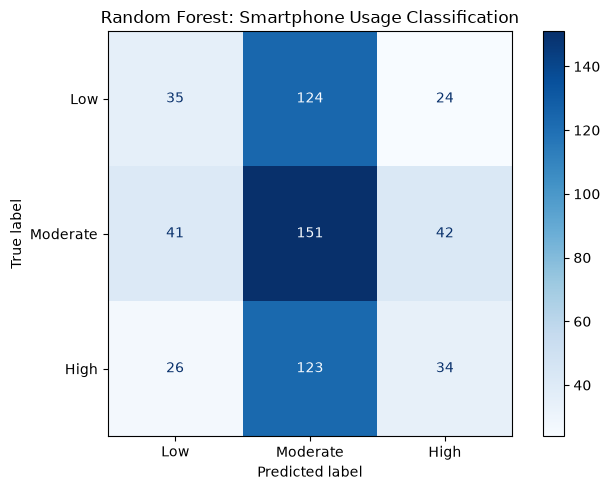

In [59]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

rf_pipeline = trained_models["Random Forest"]

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_estimator(
    rf_pipeline,
    X_test,
    y_test,
    labels=["Low", "Moderate", "High"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Random Forest: Smartphone Usage Classification")
plt.tight_layout()
plt.show()

In [60]:

# Check whether digital activity hours directly
# reproduce the daily smartphone usage measure

activity_total = df[
    ["Time_on_Social_Media",
     "Time_on_Gaming",
     "Time_on_Education"]
].sum(axis=1)

print("Correlation with daily usage:")
print(round(activity_total.corr(df["Daily_Usage_Hours"]), 3))

print("Percentage of exact matches:")
print(round(
    (activity_total.round(2) ==
     df["Daily_Usage_Hours"].round(2)).mean() * 100, 2
))

Correlation with daily usage:
-0.009
Percentage of exact matches:
1.87
